
# Spark for Big Data Preprocessing and Statistical Analysis

## Airline Flight Delay Classification Using Logistic Regression

**Student:** Sabina Bimbi  
**Course:** Big Data Analytics (SAT5165)  
**Dataset:** 2015 Airline Flight Delays  
**Method:** Logistic Regression using PySpark MLlib

### Project Overview

This project uses Apache Spark (PySpark) to analyze the 2015 airline flight delays dataset and build a Logistic Regression classification model to predict whether a flight will arrive at least 15 minutes late.

The implementation includes data exploration, cleaning, feature engineering, model training, and evaluation using Spark DataFrames and MLlib.

The performance of the complete workflow was also evaluated using a Spark standalone cluster with 1, 2, and 4 executors. Each configuration was tested three times to compare execution time, speedup, and scalability.



## 1. Environment Setup

In [ ]:

%pip -q install pyspark psutil


In [ ]:

# Python libraries
import os
import time
import subprocess
import statistics
import ast
import json
import platform
import shutil
import socket
import urllib.request
import importlib.util
import csv
from pathlib import Path

# System information
import psutil

# Data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Google Colab
from google.colab import drive

# PySpark
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Machine learning
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

print("All libraries imported successfully.")
print("PySpark version:", pyspark.__version__)


All libraries imported successfully.
PySpark version: 4.0.4



### 1.1 Dataset Location

The dataset was obtained from Kaggle and contains flight records from 2015. Four CSV files are used in the project:

- `flights.csv`: Flight schedules, delays, distances, and cancellation information.
- `airlines.csv`: Airline codes and names.
- `airports.csv`: Airport codes and geographical information.
- `cancellation_codes.csv`: Descriptions of flight cancellation reasons.

The files are stored in Google Drive for access during the Colab session.


In [ ]:

drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/spark_project/data"

# Checking the dataset files
for file in sorted(os.listdir(DATA_DIR)):
    file_path = os.path.join(DATA_DIR, file)
    size_mb = os.path.getsize(file_path) / 1e6
    print(f"{file}: {size_mb:.1f} MB")


Mounted at /content/drive
airlines.csv: 0.0 MB
airports.csv: 0.0 MB
cancellation_codes.csv: 0.0 MB
flights.csv: 592.4 MB



### 1.2 Spark Session

A Spark session is initialized to process the dataset using Spark DataFrames. The initial implementation uses local mode for development and testing.

The final performance experiments used a Spark standalone cluster with different executor configurations.


In [ ]:

spark = (
    SparkSession.builder
    .appName("FlightDelayLogisticRegression")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)


Spark version: 4.0.4
Spark master: local[*]



## 2. Data Loading and Initial Exploration

The four CSV files are loaded into Spark DataFrames. Schema inference is disabled, and the required numeric columns are converted explicitly to their appropriate data types.

This approach avoids the additional full-data scan associated with automatic schema inference and provides control over the data types used during preprocessing.


In [ ]:

flights = spark.read.csv(f"{DATA_DIR}/flights.csv", header=True)
airlines = spark.read.csv(f"{DATA_DIR}/airlines.csv", header=True)
airports = spark.read.csv(f"{DATA_DIR}/airports.csv", header=True)
codes = spark.read.csv(f"{DATA_DIR}/cancellation_codes.csv", header=True)

print("CSV files loaded successfully.")

print("\nFlight dataset columns:")
print(flights.columns)

print("\nTotal flight records:", flights.count())


CSV files loaded successfully.

Flight dataset columns:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

Total flight records: 5819079


In [ ]:

# Converting the required columns to numeric data types
numeric_columns = {
    "MONTH": "int",
    "DAY_OF_WEEK": "int",
    "SCHEDULED_DEPARTURE": "int",
    "DISTANCE": "double",
    "SCHEDULED_TIME": "double",
    "ARRIVAL_DELAY": "double",
    "CANCELLED": "int",
    "DIVERTED": "int"
}

for column, data_type in numeric_columns.items():
    flights = flights.withColumn(
        column,
        F.col(column).cast(data_type)
    )

flights.printSchema()


root
 |-- YEAR: string (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: string (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: string (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: string (nullable = true)
 |-- DEPARTURE_DELAY: string (nullable = true)
 |-- TAXI_OUT: string (nullable = true)
 |-- WHEELS_OFF: string (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: string (nullable = true)
 |-- AIR_TIME: string (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: string (nullable = true)
 |-- TAXI_IN: string (nullable = true)
 |-- SCHEDULED_ARRIVAL: string (nullable = true)
 |-- ARRIVAL_TIME: string (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = true)
 |-


### 2.1 Flight Status and Delay Analysis

Before training the classification model, the dataset is examined for cancelled flights, diverted flights, and missing arrival delay values.

Cancelled and diverted flights are excluded from the classification dataset because their arrival outcomes are not directly comparable to normally completed flights.

A flight is classified as delayed when its arrival delay is 15 minutes or more.


In [ ]:

# Checking cancellations, diversions, and missing arrival delays
flights.select(
    F.sum("CANCELLED").alias("cancelled"),
    F.sum("DIVERTED").alias("diverted"),
    F.sum(F.col("ARRIVAL_DELAY").isNull().cast("int")).alias("missing_arrival_delay")
).show()

# Excluding cancelled and diverted flights
normal_flights = flights.filter(
    (F.col("CANCELLED") == 0) &
    (F.col("DIVERTED") == 0)
)

# Counting completed flights and flights delayed by at least 15 minutes
normal_flights.select(
    F.count("*").alias("normal_flights"),
    F.sum(
        F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)
    ).alias("late_flights")
).show()


+---------+--------+---------------------+
|cancelled|diverted|missing_arrival_delay|
+---------+--------+---------------------+
|    89884|   15187|               105071|
+---------+--------+---------------------+

+--------------+------------+
|normal_flights|late_flights|
+--------------+------------+
|       5714008|     1063439|
+--------------+------------+




## 3. Airport Code Validation

The flight dataset contains origin and destination airport codes that need to be matched with the airport reference table.

A left anti join is used to identify flights whose airport codes are not present in `airports.csv`.

The unmatched records are grouped by month to determine whether the mismatches are concentrated in specific periods. This helps assess the potential impact of removing or retaining these records during preprocessing.


In [ ]:

# Identifying origin airports missing from the reference table
unmatched_origin = flights.join(
    airports,
    flights.ORIGIN_AIRPORT == airports.IATA_CODE,
    "left_anti"
)

print("Total flights with unmatched origin airports:", unmatched_origin.count())
print("Unique unmatched origin codes:", unmatched_origin.select("ORIGIN_AIRPORT").distinct().count())

# Monthly distribution of unmatched origin airports
origin_monthly = (
    unmatched_origin
    .groupBy("MONTH")
    .count()
    .orderBy("MONTH")
)

origin_monthly.show(12)


Total flights with unmatched origin airports: 486165
Unique unmatched origin codes: 306
+-----+------+
|MONTH| count|
+-----+------+
|   10|486165|
+-----+------+



In [ ]:

# Identifying destination airports missing from the reference table
unmatched_destination = flights.join(
    airports,
    flights.DESTINATION_AIRPORT == airports.IATA_CODE,
    "left_anti"
)

print("Total flights with unmatched destination airports:", unmatched_destination.count())
print("Unique unmatched destination codes:", unmatched_destination.select("DESTINATION_AIRPORT").distinct().count())

# Monthly distribution of unmatched destination airports
destination_monthly = (
    unmatched_destination
    .groupBy("MONTH")
    .count()
    .orderBy("MONTH")
)

destination_monthly.show(12)


Total flights with unmatched destination airports: 486165
Unique unmatched destination codes: 307
+-----+------+
|MONTH| count|
+-----+------+
|   10|486165|
+-----+------+



In [ ]:

# Total flights per month
monthly_flights = (
    flights.groupBy("MONTH")
    .count()
    .withColumnRenamed("count", "total_flights")
)

# Renaming the unmatched counts
origin_counts = origin_monthly.withColumnRenamed("count", "unmatched_origin")
destination_counts = destination_monthly.withColumnRenamed("count", "unmatched_destination")

# Combining monthly results
airport_comparison = (
    monthly_flights
    .join(origin_counts, "MONTH", "left")
    .join(destination_counts, "MONTH", "left")
    .fillna(0, subset=["unmatched_origin", "unmatched_destination"])
    .withColumn(
        "origin_percent",
        F.round(F.col("unmatched_origin") / F.col("total_flights") * 100, 2)
    )
    .withColumn(
        "destination_percent",
        F.round(F.col("unmatched_destination") / F.col("total_flights") * 100, 2)
    )
    .orderBy("MONTH")
)

airport_comparison.show(12, truncate=False)


+-----+-------------+----------------+---------------------+--------------+-------------------+
|MONTH|total_flights|unmatched_origin|unmatched_destination|origin_percent|destination_percent|
+-----+-------------+----------------+---------------------+--------------+-------------------+
|1    |469968       |0               |0                    |0.0           |0.0                |
|2    |429191       |0               |0                    |0.0           |0.0                |
|3    |504312       |0               |0                    |0.0           |0.0                |
|4    |485151       |0               |0                    |0.0           |0.0                |
|5    |496993       |0               |0                    |0.0           |0.0                |
|6    |503897       |0               |0                    |0.0           |0.0                |
|7    |520718       |0               |0                    |0.0           |0.0                |
|8    |510536       |0               |0 

## 4. Data Cleaning and Preprocessing

The dataset is cleaned to prepare it for flight delay classification. This includes identifying cancellation reasons, removing cancelled and diverted flights, and excluding records with inconsistent airport codes.

The initial exploration showed that all 486,165 flights recorded in October have origin and destination airport codes that do not match the airport reference table. October is therefore excluded to maintain consistent airport information across the remaining months.

The cleaned flight records are then joined with the airline and airport reference tables using Spark DataFrames.

In [ ]:
# Joining cancellation descriptions using the shared cancellation code
flights_with_codes = flights.join(
    F.broadcast(codes),
    on="CANCELLATION_REASON",
    how="left"
)

print("Total records after joining cancellation codes:")
print(flights_with_codes.count())

flights_with_codes.select(
    "CANCELLED",
    "CANCELLATION_REASON",
    "CANCELLATION_DESCRIPTION"
).show(10, truncate=False)

Total records after joining cancellation codes:
5819079
+---------+-------------------+------------------------+
|CANCELLED|CANCELLATION_REASON|CANCELLATION_DESCRIPTION|
+---------+-------------------+------------------------+
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
|0        |NULL               |NULL                    |
+---------+-------------------+------------------------+
only showing top 10 rows


### 4.1 Cancellation Analysis

Cancellation reasons are examined before removing cancelled flights from the dataset.

The cancellation reference table provides descriptions for airline-related, weather-related, national air system, and security cancellations. These categories are summarized to understand the distribution of cancelled flights.

In [ ]:
# Counting cancelled flights by cancellation reason
cancellation_summary = (
    flights_with_codes
    .filter(F.col("CANCELLED") == 1)
    .groupBy("CANCELLATION_DESCRIPTION")
    .count()
    .orderBy(F.desc("count"))
)

print("Cancellation reasons:")
cancellation_summary.show(truncate=False)

print("Total cancelled flights:")
print(
    flights_with_codes
    .filter(F.col("CANCELLED") == 1)
    .count()
)

Cancellation reasons:
+------------------------+-----+
|CANCELLATION_DESCRIPTION|count|
+------------------------+-----+
|Weather                 |48851|
|Airline/Carrier         |25262|
|National Air System     |15749|
|Security                |22   |
+------------------------+-----+

Total cancelled flights:
89884


### 4.2 Removing Cancelled and Diverted Flights

Cancelled and diverted flights are excluded because the classification model focuses on flights that completed their scheduled journeys.

The remaining records are checked to confirm the number of completed flights before applying the airport-code cleaning decision.

In [ ]:
# Keeping flights that were not cancelled or diverted
cleaned_flights = flights_with_codes.filter(
    (F.col("CANCELLED") == 0) &
    (F.col("DIVERTED") == 0)
)

print("Flights remaining after removing cancellations and diversions:")
print(cleaned_flights.count())

print("Missing arrival delay values:")
cleaned_flights.select(
    F.sum(
        F.col("ARRIVAL_DELAY").isNull().cast("int")
    ).alias("missing_arrival_delay")
).show()

Flights remaining after removing cancellations and diversions:
5714008
Missing arrival delay values:
+---------------------+
|missing_arrival_delay|
+---------------------+
|                    0|
+---------------------+



### 4.3 Handling Inconsistent Airport Codes

The airport-code validation identified 486,165 records in October whose origin and destination airport codes do not match the airport reference table.

These records use numeric airport identifiers instead of the three-letter codes used in the other months.

October is excluded from the analysis to maintain consistent airport information. This decision is applied to both team members' methods and will be documented as a limitation in the final report.

In [ ]:
# Counting completed flights recorded in October
october_flights = cleaned_flights.filter(
    F.col("MONTH") == 10
).count()

print("Completed flights in October:", october_flights)

# Excluding October from the classification dataset
cleaned_flights = cleaned_flights.filter(
    F.col("MONTH") != 10
)

print("Flights remaining after excluding October:")
print(cleaned_flights.count())

# Checking the remaining months
cleaned_flights.groupBy("MONTH").count().orderBy("MONTH").show(12)

Completed flights in October: 482878
Flights remaining after excluding October:
5231130
+-----+------+
|MONTH| count|
+-----+------+
|    1|457013|
|    2|407663|
|    3|492138|
|    4|479251|
|    5|489641|
|    6|492847|
|    7|514384|
|    8|503956|
|    9|462153|
|   11|462367|
|   12|469717|
+-----+------+



### 4.4 Airline Information

The flight records contain airline codes, while the airline reference table provides the corresponding airline names.

A broadcast left join is used to add airline names without removing flight records that may have unmatched airline codes.

In [ ]:
# Renaming the airline reference column
airline_lookup = airlines.withColumnRenamed(
    "AIRLINE",
    "AIRLINE_NAME"
)

# Joining airline names using the airline code
cleaned_flights = cleaned_flights.join(
    F.broadcast(airline_lookup),
    cleaned_flights.AIRLINE == airline_lookup.IATA_CODE,
    "left"
)

print("Total flights after airline join:")
print(cleaned_flights.count())

# Checking missing airline names
cleaned_flights.select(
    F.sum(
        F.col("AIRLINE_NAME").isNull().cast("int")
    ).alias("missing_airline_names")
).show()

cleaned_flights.select(
    "AIRLINE",
    "AIRLINE_NAME"
).show(10, truncate=False)

Total flights after airline join:
5231130
+---------------------+
|missing_airline_names|
+---------------------+
|                    0|
+---------------------+

+-------+----------------------+
|AIRLINE|AIRLINE_NAME          |
+-------+----------------------+
|AS     |Alaska Airlines Inc.  |
|AA     |American Airlines Inc.|
|US     |US Airways Inc.       |
|AA     |American Airlines Inc.|
|AS     |Alaska Airlines Inc.  |
|DL     |Delta Air Lines Inc.  |
|NK     |Spirit Air Lines      |
|US     |US Airways Inc.       |
|AA     |American Airlines Inc.|
|DL     |Delta Air Lines Inc.  |
+-------+----------------------+
only showing top 10 rows


### 4.5 Airport Information

The airport reference table is joined twice to obtain information about both the origin and destination airports.

Column names are renamed before joining to distinguish origin information from destination information.

Broadcast left joins are used to preserve the flight records while adding airport names and geographical information.

In [ ]:
# Preparing origin airport information
origin_airports = airports.select(
    F.col("IATA_CODE").alias("ORIGIN_CODE"),
    F.col("AIRPORT").alias("ORIGIN_NAME"),
    F.col("STATE").alias("ORIGIN_STATE")
)

# Preparing destination airport information
destination_airports = airports.select(
    F.col("IATA_CODE").alias("DEST_CODE"),
    F.col("AIRPORT").alias("DEST_NAME"),
    F.col("STATE").alias("DEST_STATE")
)

print("Origin airport reference:")
origin_airports.show(5, truncate=False)

print("Destination airport reference:")
destination_airports.show(5, truncate=False)

Origin airport reference:
+-----------+-----------------------------------+------------+
|ORIGIN_CODE|ORIGIN_NAME                        |ORIGIN_STATE|
+-----------+-----------------------------------+------------+
|ABE        |Lehigh Valley International Airport|PA          |
|ABI        |Abilene Regional Airport           |TX          |
|ABQ        |Albuquerque International Sunport  |NM          |
|ABR        |Aberdeen Regional Airport          |SD          |
|ABY        |Southwest Georgia Regional Airport |GA          |
+-----------+-----------------------------------+------------+
only showing top 5 rows
Destination airport reference:
+---------+-----------------------------------+----------+
|DEST_CODE|DEST_NAME                          |DEST_STATE|
+---------+-----------------------------------+----------+
|ABE      |Lehigh Valley International Airport|PA        |
|ABI      |Abilene Regional Airport           |TX        |
|ABQ      |Albuquerque International Sunport  |NM        

In [ ]:
# Joining origin airport information
cleaned_flights = cleaned_flights.join(
    F.broadcast(origin_airports),
    cleaned_flights.ORIGIN_AIRPORT == origin_airports.ORIGIN_CODE,
    "left"
)

# Joining destination airport information
cleaned_flights = cleaned_flights.join(
    F.broadcast(destination_airports),
    cleaned_flights.DESTINATION_AIRPORT == destination_airports.DEST_CODE,
    "left"
)

print("Total flights after airport joins:")
print(cleaned_flights.count())

cleaned_flights.select(
    "ORIGIN_AIRPORT",
    "ORIGIN_NAME",
    "ORIGIN_STATE",
    "DESTINATION_AIRPORT",
    "DEST_NAME",
    "DEST_STATE"
).show(10, truncate=False)

Total flights after airport joins:
5231130
+--------------+-------------------------------------------+------------+-------------------+------------------------------------------------+----------+
|ORIGIN_AIRPORT|ORIGIN_NAME                                |ORIGIN_STATE|DESTINATION_AIRPORT|DEST_NAME                                       |DEST_STATE|
+--------------+-------------------------------------------+------------+-------------------+------------------------------------------------+----------+
|ANC           |Ted Stevens Anchorage International Airport|AK          |SEA                |Seattle-Tacoma International Airport            |WA        |
|LAX           |Los Angeles International Airport          |CA          |PBI                |Palm Beach International Airport                |FL        |
|SFO           |San Francisco International Airport        |CA          |CLT                |Charlotte Douglas International Airport         |NC        |
|LAX           |Los Angeles Inter

### 4.6 Missing Value Validation

The cleaned dataset is checked for missing values in the columns required for classification.

This includes scheduled flight information, airline names, airport codes, and geographical information.

The results are used to identify any remaining data quality issues before feature engineering.

In [ ]:
# Columns required for classification
feature_columns = [
    "MONTH",
    "DAY_OF_WEEK",
    "DISTANCE",
    "SCHEDULED_TIME",
    "SCHEDULED_DEPARTURE",
    "AIRLINE_NAME",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "ORIGIN_STATE",
    "DEST_STATE",
    "ARRIVAL_DELAY"
]

# Counting missing values in each column
missing_values = cleaned_flights.select([
    F.sum(
        F.col(column).isNull().cast("int")
    ).alias(column)
    for column in feature_columns
])

print("Missing values in classification columns:")
missing_values.show(truncate=False)

Missing values in classification columns:
+-----+-----------+--------+--------------+-------------------+------------+--------------+-------------------+------------+----------+-------------+
|MONTH|DAY_OF_WEEK|DISTANCE|SCHEDULED_TIME|SCHEDULED_DEPARTURE|AIRLINE_NAME|ORIGIN_AIRPORT|DESTINATION_AIRPORT|ORIGIN_STATE|DEST_STATE|ARRIVAL_DELAY|
+-----+-----------+--------+--------------+-------------------+------------+--------------+-------------------+------------+----------+-------------+
|0    |0          |0       |0             |0                  |0           |0             |0                  |0           |0         |0            |
+-----+-----------+--------+--------------+-------------------+------------+--------------+-------------------+------------+----------+-------------+



### 4.7 Creating the Classification Target

A binary target variable named `label` is created using arrival delay.

Flights arriving at least 15 minutes late are assigned a label of 1.0, while flights arriving less than 15 minutes late are assigned a label of 0.0.

This target will be used to train the Logistic Regression classification model.

In [ ]:
# Creating the binary delay classification label
cleaned_flights = cleaned_flights.withColumn(
    "label",
    F.when(F.col("ARRIVAL_DELAY") >= 15, 1.0)
     .otherwise(0.0)
)

# Counting flights in each class
print("Flight delay classification:")
cleaned_flights.groupBy("label").count().orderBy("label").show()

# Checking the final dataset size
print("Final records:", cleaned_flights.count())

Flight delay classification:
+-----+-------+
|label|  count|
+-----+-------+
|  0.0|4227770|
|  1.0|1003360|
+-----+-------+

Final records: 5231130



### 4.8 Preprocessing Summary

The original dataset contained **5,819,079 flight records**.

After excluding **89,884 cancelled flights** and **15,187 diverted flights**, **5,714,008 completed flights** remained.

An additional **482,878 completed flights** from October were excluded because their numeric airport identifiers did not match the airport reference table.

The final cleaned dataset contains **5,231,130 flights**. Joining the airline and airport reference tables did not change the record count.

All selected classification columns were checked for missing values, and **zero missing values** were identified. No additional records needed to be removed.

The binary classification target contains **4,227,770 flights (80.8%)** labeled **0** (not delayed by 15 minutes or more) and **1,003,360 flights (19.2%)** labeled **1** (delayed by at least 15 minutes).

October's exclusion represents a limitation because the final dataset does not cover all twelve months of 2015.



## 5. Feature Engineering

Feature engineering prepares the cleaned dataset for Logistic Regression by selecting and transforming the variables used for prediction.

The model aims to predict whether a flight will arrive **15 minutes or more late**, using information available before departure.

The selected features include:

- **MONTH:** Month of the scheduled flight.
- **DAY_OF_WEEK:** Day of the week.
- **DISTANCE:** Distance between the origin and destination airports.
- **SCHEDULED_TIME:** Planned flight duration in minutes.
- **SCHEDULED_DEPARTURE:** Scheduled departure time, used to calculate the departure hour.
- **AIRLINE_NAME:** Airline operating the flight.
- **ORIGIN_AIRPORT:** Departure airport.
- **DESTINATION_AIRPORT:** Arrival airport.
- **ORIGIN_STATE:** State of the departure airport.
- **DEST_STATE:** State of the arrival airport.

Categorical features will be encoded using PySpark MLlib, while numerical features will be combined into a feature vector.

Actual arrival delay and other information recorded during or after the flight are excluded from the input features to prevent **data leakage**.



### 5.1 Extracting Scheduled Departure Hour

The `SCHEDULED_DEPARTURE` column records departure times using the HHMM format.

For example, **0830** represents 8:30 AM, while **1745** represents 5:45 PM.

A new column named `DEP_HOUR` is created by dividing the scheduled departure time by 100 and taking the integer part.

This provides the scheduled departure hour as a numerical feature ranging from **0 to 23**.


In [ ]:

# Extracting the scheduled departure hour from HHMM format
model_data = cleaned_flights.withColumn(
    "DEP_HOUR",
    F.floor(F.col("SCHEDULED_DEPARTURE") / 100).cast("int")
)

# Checking the scheduled departure times and extracted hours
model_data.select(
    "SCHEDULED_DEPARTURE",
    "DEP_HOUR"
).show(15)

# Checking the range of departure hours
model_data.select(
    F.min("DEP_HOUR").alias("min_hour"),
    F.max("DEP_HOUR").alias("max_hour")
).show()

# Checking for invalid departure hours
invalid_hours = model_data.filter(
    F.col("DEP_HOUR").isNull() |
    (F.col("DEP_HOUR") < 0) |
    (F.col("DEP_HOUR") > 23)
).count()

print("Records with invalid departure hours:", invalid_hours)


+-------------------+--------+
|SCHEDULED_DEPARTURE|DEP_HOUR|
+-------------------+--------+
|                  5|       0|
|                 10|       0|
|                 20|       0|
|                 20|       0|
|                 25|       0|
|                 25|       0|
|                 25|       0|
|                 30|       0|
|                 30|       0|
|                 30|       0|
|                 30|       0|
|                 35|       0|
|                 35|       0|
|                 40|       0|
|                 40|       0|
+-------------------+--------+
only showing top 15 rows
+--------+--------+
|min_hour|max_hour|
+--------+--------+
|       0|      23|
+--------+--------+

Records with invalid departure hours: 0



### 5.2 Selecting Model Features

The classification dataset is reduced to the selected predictor variables and the binary target label.

The scheduled departure hour is used instead of the original HHMM departure time.

The categorical and numerical variables are retained for further transformations using PySpark MLlib.


In [ ]:

# Categorical features
categorical_features = [
    "AIRLINE_NAME",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "ORIGIN_STATE",
    "DEST_STATE"
]

# Numerical features
numerical_features = [
    "MONTH",
    "DAY_OF_WEEK",
    "DISTANCE",
    "SCHEDULED_TIME",
    "DEP_HOUR"
]

# Selecting predictors and classification label
model_data = model_data.select(
    *categorical_features,
    *numerical_features,
    "label"
)

print("Selected model columns:")
print(model_data.columns)

print("Total model records:")
print(model_data.count())

model_data.show(5, truncate=False)


Selected model columns:
['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE', 'MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR', 'label']
Total model records:
5231130
+----------------------+--------------+-------------------+------------+----------+-----+-----------+--------+--------------+--------+-----+
|AIRLINE_NAME          |ORIGIN_AIRPORT|DESTINATION_AIRPORT|ORIGIN_STATE|DEST_STATE|MONTH|DAY_OF_WEEK|DISTANCE|SCHEDULED_TIME|DEP_HOUR|label|
+----------------------+--------------+-------------------+------------+----------+-----+-----------+--------+--------------+--------+-----+
|Alaska Airlines Inc.  |ANC           |SEA                |AK          |WA        |1    |4          |1448.0  |205.0         |0       |0.0  |
|American Airlines Inc.|LAX           |PBI                |CA          |FL        |1    |4          |2330.0  |280.0         |0       |0.0  |
|US Airways Inc.       |SFO           |CLT                |CA          |NC     


### 5.3 Encoding Categorical Features

The selected categorical variables contain text values that cannot be used directly by Logistic Regression.

**StringIndexer** converts each category into a numerical index, while **OneHotEncoder** transforms the indices into binary feature vectors.

This approach allows the model to learn from airline, airport, and state information without treating the categories as ordered numerical values.



In [ ]:

# Creating numerical indices for categorical features
indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=f"{column}_INDEX",
        handleInvalid="keep"
    )
    for column in categorical_features
]

# Encoding the indexed categories
encoders = [
    OneHotEncoder(
        inputCol=f"{column}_INDEX",
        outputCol=f"{column}_OHE"
    )
    for column in categorical_features
]

print("Categorical features:", categorical_features)
print("Number of indexers:", len(indexers))
print("Number of encoders:", len(encoders))

for column in categorical_features:
    print(f"{column} -> {column}_INDEX -> {column}_OHE")


Categorical features: ['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE']
Number of indexers: 5
Number of encoders: 5
AIRLINE_NAME -> AIRLINE_NAME_INDEX -> AIRLINE_NAME_OHE
ORIGIN_AIRPORT -> ORIGIN_AIRPORT_INDEX -> ORIGIN_AIRPORT_OHE
DESTINATION_AIRPORT -> DESTINATION_AIRPORT_INDEX -> DESTINATION_AIRPORT_OHE
ORIGIN_STATE -> ORIGIN_STATE_INDEX -> ORIGIN_STATE_OHE
DEST_STATE -> DEST_STATE_INDEX -> DEST_STATE_OHE



### 5.4 Assembling the Feature Vector

Logistic Regression requires all predictor variables to be combined into a single feature vector.

**VectorAssembler** combines the numerical flight features and the one-hot encoded categorical features into a column named `features`.

The resulting vector represents the information used by the classification model to predict flight delays.


In [ ]:

# Collecting encoded categorical feature names
encoded_features = [
    f"{column}_OHE"
    for column in categorical_features
]

# Combining numerical and encoded categorical features
assembler = VectorAssembler(
    inputCols=numerical_features + encoded_features,
    outputCol="features",
    handleInvalid="error"
)

print("Numerical features:", numerical_features)
print("Encoded categorical features:", encoded_features)
print("Total feature groups:", len(assembler.getInputCols()))


Numerical features: ['MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR']
Encoded categorical features: ['AIRLINE_NAME_OHE', 'ORIGIN_AIRPORT_OHE', 'DESTINATION_AIRPORT_OHE', 'ORIGIN_STATE_OHE', 'DEST_STATE_OHE']
Total feature groups: 10



### 5.5 Training and Testing Data

The cleaned dataset is divided into **80% training data** and **20% testing data**.

A fixed random seed of **42** is used to make the split reproducible.


In [ ]:

# Splitting the data into training and testing sets
train_data, test_data = model_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Counting records in each dataset
train_count = train_data.count()
test_count = test_data.count()

print("Training records:", train_count)
print("Testing records:", test_count)
print("Total records:", train_count + test_count)

print("Training percentage:", round(train_count / (train_count + test_count) * 100, 2))
print("Testing percentage:", round(test_count / (train_count + test_count) * 100, 2))


Training records: 4184643
Testing records: 1046487
Total records: 5231130
Training percentage: 80.0
Testing percentage: 20.0



## 6. Logistic Regression Model Training

For this project, I selected **Logistic Regression** to classify flights based on whether they arrived at least **15 minutes late**.

The model uses scheduled flight information to estimate the probability of a flight being delayed. I defined the target variable as **1 for delayed flights** and **0 for flights arriving less than 15 minutes late**.

I used PySpark MLlib to build a machine learning pipeline that handles categorical encoding, feature assembly, and classification. The pipeline is fitted only on the training data to avoid information leakage from the test set.



### 6.1 Building the Machine Learning Pipeline

I created a PySpark MLlib pipeline to combine feature preprocessing and Logistic Regression into one workflow.

The pipeline consists of **5 StringIndexers**, **5 OneHotEncoders**, **1 VectorAssembler**, and **1 Logistic Regression classifier**, giving a total of **12 stages**.

I configured Logistic Regression with a maximum of **20 iterations** and a regularization parameter of **0.01** to help control model complexity.


In [ ]:

# Configuring the Logistic Regression classifier
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=20,
    regParam=0.01
)

# Combining feature transformations and classification
pipeline = Pipeline(
    stages=indexers + encoders + [assembler, lr]
)

print("Pipeline stages:")
for i, stage in enumerate(pipeline.getStages(), start=1):
    print(f"{i}. {stage.__class__.__name__}")

print("Maximum iterations:", lr.getMaxIter())
print("Regularization parameter:", lr.getRegParam())


Pipeline stages:
1. StringIndexer
2. StringIndexer
3. StringIndexer
4. StringIndexer
5. StringIndexer
6. OneHotEncoder
7. OneHotEncoder
8. OneHotEncoder
9. OneHotEncoder
10. OneHotEncoder
11. VectorAssembler
12. LogisticRegression
Maximum iterations: 20
Regularization parameter: 0.01



### 6.2 Training the Logistic Regression Model

I used **4,184,643 flight records (80%)** to train the model, while the remaining **1,046,487 records (20%)** were reserved for testing.

During training, the pipeline learns the categorical mappings, transforms the selected features, and fits the Logistic Regression classifier.

I also measured the training time using Python's `time.perf_counter()` to examine the computational cost of fitting the pipeline.

This initial measurement is separate from the final Spark standalone-cluster experiments, where I aimed to compare execution times using **1, 2, and 4 executors**.


In [ ]:

# Measuring the time required to train the pipeline
start_time = time.perf_counter()

pipeline_model = pipeline.fit(train_data)

training_time = time.perf_counter() - start_time

print("Logistic Regression training completed.")
print(f"Training time: {training_time:.2f} seconds")

# Accessing the trained Logistic Regression model
lr_model = pipeline_model.stages[-1]

print("Number of iterations:", lr_model.summary.totalIterations)
print("Number of model coefficients:", len(lr_model.coefficients))
print("Model intercept:", lr_model.intercept)


Logistic Regression training completed.
Training time: 470.00 seconds
Number of iterations: 20
Number of model coefficients: 771
Model intercept: -2.1784530214288202



## 7. Logistic Regression Model Evaluation

In this section, I evaluated the performance of my trained Logistic Regression model using the **1,046,487 flight records** reserved for testing.

I generated predictions and assess the model using **accuracy, precision, recall, F1 score, and ROC-AUC**.

Since delayed flights represent approximately **19.2%** of the cleaned dataset, I considered multiple evaluation metrics rather than relying on accuracy alone.

I also examined the confusion matrix to understand how well the model identifies delayed flights and where classification errors occur.


In [ ]:

# Applying the trained pipeline to the testing dataset
predictions = pipeline_model.transform(test_data)

# Displaying actual labels, predicted labels, and probabilities
predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

# Verifying the number of predictions
prediction_count = predictions.count()

print("Total test records:", test_count)
print("Total predictions:", prediction_count)


+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0.0  |0.0       |[0.8274090557039692,0.17259094429603083]|
|0.0  |0.0       |[0.830746918525832,0.16925308147416795] |
|0.0  |0.0       |[0.8340331764864822,0.16596682351351777]|
|0.0  |0.0       |[0.8372681265491273,0.1627318734508727] |
|0.0  |0.0       |[0.8404520844977595,0.15954791550224046]|
|0.0  |0.0       |[0.8435853840842008,0.1564146159157992] |
|0.0  |0.0       |[0.8466683761828473,0.1533316238171527] |
|0.0  |0.0       |[0.8340168769162367,0.16598312308376328]|
|0.0  |0.0       |[0.8404362947218361,0.15956370527816388]|
|0.0  |0.0       |[0.8404362947218361,0.15956370527816388]|
+-----+----------+----------------------------------------+
only showing top 10 rows
Total test records: 1046487
Total predictions: 1046487



### 7.1 Classification Performance Metrics

I used the following metrics to evaluate my Logistic Regression model:

- **Accuracy:** To measure the overall proportion of correctly classified flights.
- **Precision:** To determine how many flights predicted as delayed are actually delayed.
- **Recall:** To measure how many actual delayed flights the model successfully identifies.
- **F1 score:** To assess the balance between precision and recall.
- **ROC-AUC:** To evaluate the model's ability to distinguish delayed from not delayed flights across different classification thresholds.

I paid particular attention to **recall and F1 score**, as identifying delayed flights is the main objective of my classification task.


In [ ]:

# Evaluating ROC-AUC
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

auc = auc_evaluator.evaluate(predictions)

# Evaluating accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = accuracy_evaluator.evaluate(predictions)

# Calculating confusion matrix counts
confusion_counts = (
    predictions.groupBy("label", "prediction")
    .count()
    .collect()
)

counts = {
    (int(row["label"]), int(row["prediction"])): row["count"]
    for row in confusion_counts
}

tn = counts.get((0, 0), 0)
fp = counts.get((0, 1), 0)
fn = counts.get((1, 0), 0)
tp = counts.get((1, 1), 0)

# Calculating delayed-class metrics
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) else 0.0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")


Accuracy:  0.8082
Precision: 0.4428
Recall:    0.0006
F1-score:  0.0012
ROC-AUC:   0.6384



### 7.2 Confusion Matrix Analysis

I generated a confusion matrix to examine the classification results in more detail.

The matrix showed four possible outcomes:

- **True Negatives (TN):** Flights correctly predicted as not delayed.
- **False Positives (FP):** Flights incorrectly predicted as delayed.
- **False Negatives (FN):** Delayed flights incorrectly predicted as not delayed.
- **True Positives (TP):** Delayed flights correctly predicted as delayed.

This analysis helped me identify the types of prediction errors made by the model, particularly **false negatives**, where actual flight delays are missed.

I used these results alongside the evaluation metrics to assess the model's effectiveness and identify potential areas for improvement.


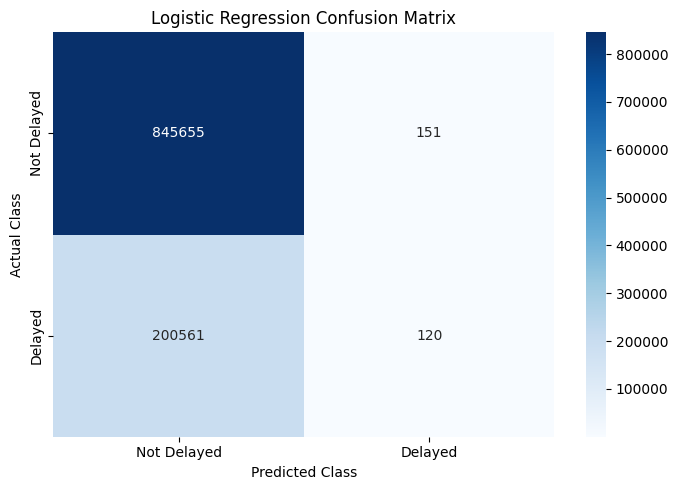

In [ ]:

# Organizing confusion matrix values
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

# Plotting the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()



### 7.3 Prediction Distribution and Baseline Comparison

I examined the distribution of predicted classes and compared my Logistic Regression model's accuracy against a majority-class baseline.

The initial evaluation showed an accuracy of **80.82%**, but the model identifies only **120 out of 200,681 actual delayed flights**. This results in a recall of approximately **0.06%**, indicating that the model predicts very few flights as delayed.

I compared the model's performance with a baseline that classifies every flight as not delayed. This comparison helped me determine whether the model provides a meaningful improvement over predicting the majority class.

Based on these findings, I investigated whether adjusting the classification threshold can improve the identification of delayed flights without retraining the model.


In [ ]:

# Examining the number of predictions in each class
print("Prediction distribution:")
predictions.groupBy("prediction").count().orderBy("prediction").show()

# Examining the confusion matrix counts
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Comparing model accuracy against the majority-class baseline
baseline_accuracy = (tn + fp) / (tn + fp + fn + tp)

print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")
print(f"Logistic Regression accuracy: {accuracy:.4f}")


Prediction distribution:
+----------+-------+
|prediction|  count|
+----------+-------+
|       0.0|1046216|
|       1.0|    271|
+----------+-------+

True Negatives: 845655
False Positives: 151
False Negatives: 200561
True Positives: 120
Majority-class baseline accuracy: 0.8082
Logistic Regression accuracy: 0.8082



### 7.4 Classification Threshold Adjustment

The initial evaluation showed that my Logistic Regression model achieves **80.82% accuracy**, but identifies very few delayed flights at the default classification threshold of **0.5**.

To investigate this limitation, I evaluated several lower probability thresholds without retraining the model.

I compared **precision, recall, F1 score, and accuracy** at each threshold to understand the trade-off between identifying more delayed flights and generating false positive predictions.

I used these results to assess whether a different threshold provides a better balance between precision and recall.


In [ ]:

# Comparing different classification thresholds
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

# Extracting the predicted probability of a delay
from pyspark.ml.functions import vector_to_array

threshold_data = predictions.select(
    "label",
    vector_to_array("probability")[1].alias("delay_probability")
)

# Calculating predictions at each threshold
for threshold in thresholds:
    threshold_data = threshold_data.withColumn(
        f"pred_{int(threshold * 100)}",
        F.when(
            F.col("delay_probability") >= threshold, 1
        ).otherwise(0)
    )

# Calculating confusion matrix counts for each threshold
metrics_exprs = []

for threshold in thresholds:
    col_name = f"pred_{int(threshold * 100)}"

    metrics_exprs.extend([
        F.sum(F.when(
            (F.col("label") == 1) & (F.col(col_name) == 1), 1
        ).otherwise(0)).alias(f"tp_{col_name}"),

        F.sum(F.when(
            (F.col("label") == 0) & (F.col(col_name) == 1), 1
        ).otherwise(0)).alias(f"fp_{col_name}"),

        F.sum(F.when(
            (F.col("label") == 1) & (F.col(col_name) == 0), 1
        ).otherwise(0)).alias(f"fn_{col_name}"),

        F.sum(F.when(
            (F.col("label") == 0) & (F.col(col_name) == 0), 1
        ).otherwise(0)).alias(f"tn_{col_name}")
    ])

counts = threshold_data.agg(*metrics_exprs).first().asDict()

# Calculating evaluation metrics
threshold_results = []

for threshold in thresholds:
    col_name = f"pred_{int(threshold * 100)}"

    tp = counts[f"tp_{col_name}"]
    fp = counts[f"fp_{col_name}"]
    fn = counts[f"fn_{col_name}"]
    tn = counts[f"tn_{col_name}"]

    precision_t = tp / (tp + fp) if tp + fp else 0
    recall_t = tp / (tp + fn) if tp + fn else 0

    f1_t = (
        2 * precision_t * recall_t / (precision_t + recall_t)
        if precision_t + recall_t else 0
    )

    accuracy_t = (tp + tn) / (tp + tn + fp + fn)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_t,
        "Precision": precision_t,
        "Recall": recall_t,
        "F1": f1_t
    })

# Displaying the results
threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall     F1
      0.10    0.2497     0.1999  0.9700 0.3315
      0.15    0.4407     0.2311  0.8238 0.3610
      0.20    0.6216     0.2693  0.5682 0.3654
      0.25    0.7263     0.2999  0.3201 0.3097
      0.30    0.7803     0.3268  0.1376 0.1937
      0.35    0.8011     0.3495  0.0434 0.0772
      0.40    0.8067     0.3706  0.0114 0.0221
      0.50    0.8082     0.4428  0.0006 0.0012



### 7.5 Validation-Based Threshold Selection

The initial threshold comparison indicated that lowering the classification threshold can substantially improve the model's ability to identify delayed flights.

Among the thresholds examined, **0.20 produced the highest F1 score of 0.3654**, with a recall of **56.82%**. However, these results were obtained from the testing dataset, so I did not use those test results alone to select the final threshold.

To make the selection more reliable, I divided the original training data into separate training and validation subsets.

I used the validation dataset to compare classification thresholds and select an appropriate value based on F1 score. I kept the testing dataset separate for final evaluation.

This approach helped reduce the risk of choosing a threshold that performs well only on the observed test data.


In [ ]:

# Splitting the original training data into fitting and validation sets
fit_data, validation_data = train_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Counting the records
fit_count = fit_data.count()
validation_count = validation_data.count()

print("Model fitting records:", fit_count)
print("Validation records:", validation_count)
print("Original training records:", train_count)
print("Combined records:", fit_count + validation_count)

# Confirming the original training records are preserved
assert fit_count + validation_count == train_count

print("Training/validation split verified.")


Model fitting records: 3347800
Validation records: 836843
Original training records: 4184643
Combined records: 4184643
Training/validation split verified.



### 7.5.1 Training the Model for Validation

I trained a separate Logistic Regression pipeline using the **3,347,800 records** allocated to model fitting.

The remaining **836,843 records** were used for validation and were not included during model training.

I retained the same feature transformations and Logistic Regression parameters used in the initial model to ensure a consistent comparison.

After training, I generated predictions on the validation dataset and used them to evaluate different classification thresholds.


In [ ]:

# Training a separate pipeline using only the fitting dataset
validation_start = time.perf_counter()

validation_pipeline_model = pipeline.fit(fit_data)

validation_training_time = time.perf_counter() - validation_start

print("Validation-stage model training completed.")
print(f"Training time: {validation_training_time:.2f} seconds")

# Accessing the trained classifier
validation_lr_model = validation_pipeline_model.stages[-1]

print(
    "Number of iterations:",
    validation_lr_model.summary.totalIterations
)

print(
    "Number of model coefficients:",
    len(validation_lr_model.coefficients)
)

print(
    "Model intercept:",
    validation_lr_model.intercept
)


Validation-stage model training completed.
Training time: 485.23 seconds
Number of iterations: 20
Number of model coefficients: 771
Model intercept: -2.177619595362461



### 7.5.2 Generating Validation Predictions

I applied the newly trained pipeline to the validation dataset to obtain predicted probabilities for delayed and not delayed flights.

I extracted the probability associated with the delayed class and used it to evaluate different classification thresholds.

This allowed me to compare threshold performance using records that were not included during model fitting.


In [ ]:

# Generating predictions using the validation dataset
validation_predictions = validation_pipeline_model.transform(
    validation_data
)

# Extracting the probability of a flight being delayed
validation_scores = validation_predictions.select(
    "label",
    vector_to_array("probability")[1].alias("delay_probability")
)

# Displaying sample validation predictions
validation_scores.show(10, truncate=False)

# Verifying validation record count
validation_prediction_count = validation_scores.count()

print("Expected validation records:", validation_count)
print("Actual validation predictions:", validation_prediction_count)

assert validation_prediction_count == validation_count

print("Validation prediction count verified.")


+-----+-------------------+
|label|delay_probability  |
+-----+-------------------+
|1.0  |0.17203982565967935|
|0.0  |0.16544210146178062|
|0.0  |0.16544210146178062|
|0.0  |0.15904879494478075|
|0.0  |0.15592799422059722|
|0.0  |0.1528572982127896 |
|0.0  |0.16541174873775366|
|0.0  |0.15901939166791357|
|0.0  |0.1648654206846376 |
|0.0  |0.1648654206846376 |
+-----+-------------------+
only showing top 10 rows
Expected validation records: 836843
Actual validation predictions: 836843
Validation prediction count verified.



### 7.5.3 Validation Threshold Comparison

I evaluated different classification thresholds using the validation dataset to determine which value provides the best balance between precision and recall.

I compared thresholds ranging from **0.10 to 0.50**, calculating accuracy, precision, recall, and F1 score for each.

I selected the threshold with the highest validation F1 score, since the objective is to identify delayed flights while balancing missed delays and false positive predictions.

This approach allowed me to select the classification threshold without using the testing dataset for model selection.


In [ ]:

# Defining thresholds for validation
validation_thresholds = [
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.50
]

# Calculating classification metrics for each threshold
validation_metrics = []

for threshold in validation_thresholds:
    validation_metrics.extend([
        F.sum(
            F.when(
                (F.col("label") == 1) &
                (F.col("delay_probability") >= threshold), 1
            ).otherwise(0)
        ).alias(f"tp_{int(threshold * 100)}"),

        F.sum(
            F.when(
                (F.col("label") == 0) &
                (F.col("delay_probability") >= threshold), 1
            ).otherwise(0)
        ).alias(f"fp_{int(threshold * 100)}"),

        F.sum(
            F.when(
                (F.col("label") == 1) &
                (F.col("delay_probability") < threshold), 1
            ).otherwise(0)
        ).alias(f"fn_{int(threshold * 100)}"),

        F.sum(
            F.when(
                (F.col("label") == 0) &
                (F.col("delay_probability") < threshold), 1
            ).otherwise(0)
        ).alias(f"tn_{int(threshold * 100)}")
    ])

# Executing the aggregation in Spark
validation_counts = (
    validation_scores.agg(*validation_metrics)
    .first()
    .asDict()
)

# Calculating accuracy, precision, recall and F1
validation_results = []

for threshold in validation_thresholds:
    key = int(threshold * 100)

    tp_v = validation_counts[f"tp_{key}"]
    fp_v = validation_counts[f"fp_{key}"]
    fn_v = validation_counts[f"fn_{key}"]
    tn_v = validation_counts[f"tn_{key}"]

    accuracy_v = (tp_v + tn_v) / (
        tp_v + tn_v + fp_v + fn_v
    )

    precision_v = (
        tp_v / (tp_v + fp_v)
        if (tp_v + fp_v) else 0
    )

    recall_v = (
        tp_v / (tp_v + fn_v)
        if (tp_v + fn_v) else 0
    )

    f1_v = (
        2 * precision_v * recall_v / (precision_v + recall_v)
        if (precision_v + recall_v) else 0
    )

    validation_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_v,
        "Precision": precision_v,
        "Recall": recall_v,
        "F1": f1_v
    })

validation_df = pd.DataFrame(validation_results)

print("Validation Threshold Results:")
print(validation_df.round(4).to_string(index=False))

# Selecting threshold with the highest validation F1-score
best_row = validation_df.loc[validation_df["F1"].idxmax()]
best_threshold = float(best_row["Threshold"])

print(f"\nBest validation threshold: {best_threshold:.2f}")
print(f"Best validation F1-score: {best_row['F1']:.4f}")


Validation Threshold Results:
 Threshold  Accuracy  Precision  Recall     F1
      0.10    0.2507     0.2006  0.9695 0.3324
      0.15    0.4424     0.2323  0.8234 0.3624
      0.20    0.6215     0.2702  0.5685 0.3663
      0.25    0.7256     0.3003  0.3202 0.3099
      0.30    0.7797     0.3270  0.1366 0.1927
      0.35    0.8004     0.3476  0.0422 0.0753
      0.40    0.8059     0.3653  0.0115 0.0223
      0.50    0.8075     0.3853  0.0006 0.0011

Best validation threshold: 0.20
Best validation F1-score: 0.3663


### Validation Threshold Performance Visualization

I compared precision, recall, and F1 scores across eight classification thresholds using the validation dataset.

The results show how changing the classification threshold affects the model's ability to identify delayed flights. Lower thresholds improve recall but also increase false positives, while higher thresholds improve precision but miss more delayed flights.

I selected **0.20 as the optimal classification threshold** because it achieved the highest validation F1 score of **0.3663**. This provides a better balance between precision and recall than the default threshold of 0.50.

The following plot illustrates these performance differences across the evaluated thresholds.

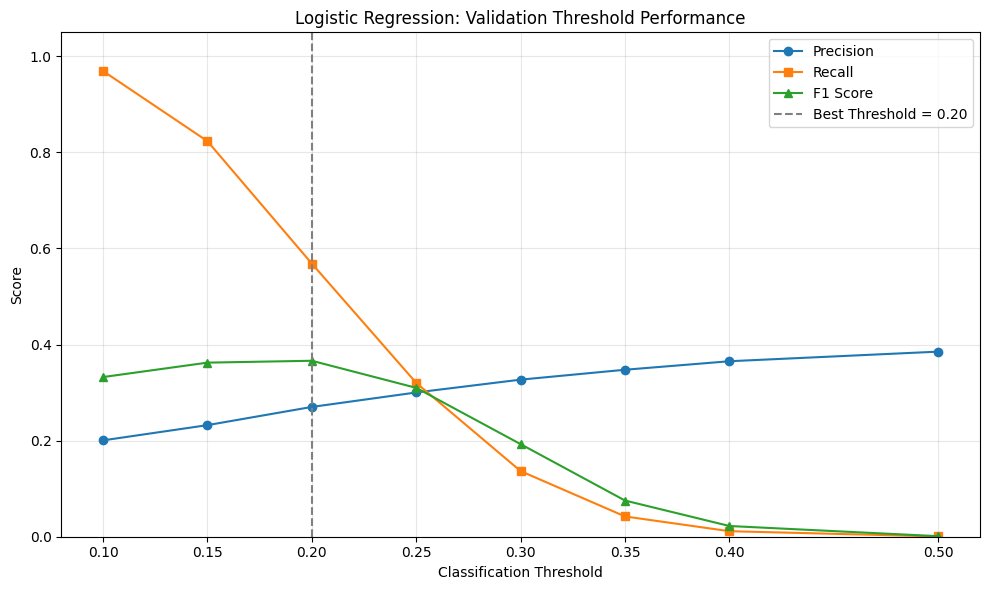

In [ ]:

# Results from the validation dataset
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

precision = [0.2006, 0.2323, 0.2702, 0.3003, 0.3270, 0.3476, 0.3653, 0.3853]
recall = [0.9695, 0.8234, 0.5685, 0.3202, 0.1366, 0.0422, 0.0115, 0.0006]
f1_scores = [0.3324, 0.3624, 0.3663, 0.3099, 0.1927, 0.0753, 0.0223, 0.0011]

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision, marker="o", label="Precision")
plt.plot(thresholds, recall, marker="s", label="Recall")
plt.plot(thresholds, f1_scores, marker="^", label="F1 Score")

# Highlight the threshold selected using validation F1
plt.axvline(
    x=0.20,
    color="gray",
    linestyle="--",
    label="Best Threshold = 0.20"
)

plt.title("Logistic Regression: Validation Threshold Performance")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


### 7.6 Final Model Evaluation Using the Selected Threshold

Based on the validation results, I selected a classification threshold of **0.20**, which achieved the highest F1 score among the eight thresholds evaluated.

I applied this threshold to my original Logistic Regression model, which was trained using **4,184,643 flight records**, and evaluated its predictions on the **1,046,487 testing records**.

I calculated accuracy, precision, recall, and F1 score, then compared these results with the default threshold of **0.50**.

I also generated an updated confusion matrix to examine how the selected threshold affects the identification of delayed flights.


In [ ]:

# Applying the threshold selected from validation
final_predictions = predictions.withColumn(
    "final_prediction",
    F.when(
        vector_to_array("probability")[1] >= best_threshold,
        1.0
    ).otherwise(0.0)
)

# Calculating the final confusion matrix
final_counts = (
    final_predictions
    .groupBy("label", "final_prediction")
    .count()
    .collect()
)

final_count_dict = {
    (int(row["label"]), int(row["final_prediction"])): row["count"]
    for row in final_counts
}

final_tn = final_count_dict.get((0, 0), 0)
final_fp = final_count_dict.get((0, 1), 0)
final_fn = final_count_dict.get((1, 0), 0)
final_tp = final_count_dict.get((1, 1), 0)

# Calculating final evaluation metrics
final_accuracy = (
    (final_tp + final_tn) /
    (final_tp + final_tn + final_fp + final_fn)
)

final_precision = (
    final_tp / (final_tp + final_fp)
    if final_tp + final_fp else 0
)

final_recall = (
    final_tp / (final_tp + final_fn)
    if final_tp + final_fn else 0
)

final_f1 = (
    2 * final_precision * final_recall /
    (final_precision + final_recall)
    if final_precision + final_recall else 0
)

print(f"Selected threshold: {best_threshold:.2f}")
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1-score:  {final_f1:.4f}")

print("\nFinal confusion matrix counts:")
print("True Negatives:", final_tn)
print("False Positives:", final_fp)
print("False Negatives:", final_fn)
print("True Positives:", final_tp)

assert (
    final_tn + final_fp + final_fn + final_tp
    == test_count
)


Selected threshold: 0.20
Accuracy:  0.6216
Precision: 0.2693
Recall:    0.5682
F1-score:  0.3654

Final confusion matrix counts:
True Negatives: 536434
False Positives: 309372
False Negatives: 86651
True Positives: 114030



### 7.7 Final Confusion Matrix

I visualized the confusion matrix using the validation-selected classification threshold of **0.20**.

I compared the numbers of correctly identified delayed flights, missed delays, and false positive predictions with the results obtained using the default threshold.

This comparison helped me assess whether the adjusted threshold improves delay detection and understand the trade-offs involved.


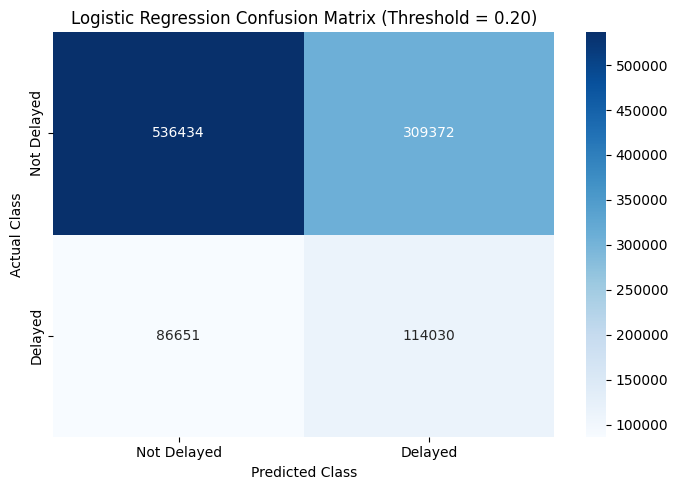

In [ ]:

# Constructing the final confusion matrix
final_confusion_matrix = np.array([
    [final_tn, final_fp],
    [final_fn, final_tp]
])

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)

plt.title(
    f"Logistic Regression Confusion Matrix "
    f"(Threshold = {best_threshold:.2f})"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()



### 7.8 Model Evaluation Summary

I summarized the performance of my Logistic Regression model by comparing the default classification threshold of **0.50** with the validation-selected threshold of **0.20**.

The initial model achieved **80.82% accuracy**, but its recall was only **0.06%**, indicating that it failed to identify nearly all delayed flights.

Using the selected threshold of **0.20**, recall increased to **56.82%** and the **delayed-flight (positive-class) F1 score** improved to **0.3654**. The model correctly identified **114,030 delayed flights**, although it also produced **309,372 false positive predictions**.

The overall accuracy decreased to **62.16%**, demonstrating the trade-off between identifying more delayed flights and maintaining classification precision.

The ROC-AUC remained **0.6384**, indicating that the threshold adjustment improved classification decisions without changing the underlying model's ability to distinguish delayed from not delayed flights.

I used these findings to discuss the strengths and limitations of Logistic Regression for flight delay prediction.



## 8. Spark Standalone Cluster Performance Experiments

In this section, I investigated how different numbers of Spark executors affect the execution time of my flight delay classification workflow.

I configured a Spark standalone cluster in Google Colab and compared **1, 2, and 4 executors**, with **1 core per executor**.

For each configuration, I performed **three runs** and recorded the execution time of the complete workflow, including data loading, preprocessing, feature engineering, model training, and evaluation.

I calculated the **mean execution time, standard deviation, and speedup** to compare performance across configurations.

### 8.1 Colab Hardware and Spark Environment

Before configuring the standalone cluster, I inspected the available CPU cores, system memory, Python version, Java version, and PySpark installation.

I used this information to document the experimental environment and identify hardware limitations that may affect the benchmark results.

**Reproducibility note:** I retained the original nine benchmark results as the recorded measurements. The benchmark cells reuse saved JSON files when present, while the setup cells can start additional Spark processes.


In [ ]:


print("=== SYSTEM INFORMATION ===")

print("Operating system:", platform.system())
print("OS version:", platform.release())
print("Python version:", platform.python_version())

print("\n=== CPU INFORMATION ===")

print("Logical CPU cores:", os.cpu_count())
print("Physical CPU cores:", psutil.cpu_count(logical=False))

print("\n=== MEMORY INFORMATION ===")

memory = psutil.virtual_memory()

print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

print("\n=== SPARK INFORMATION ===")

print("PySpark version:", pyspark.__version__)
print("Current Spark version:", spark.version)
print("Current Spark master:", spark.sparkContext.master)

print("\n=== JAVA INFORMATION ===")

subprocess.run(["java", "-version"], check=False)

print("\n=== SPARK INSTALLATION ===")

spark_home = os.environ.get("SPARK_HOME")

if spark_home:
    print("SPARK_HOME:", spark_home)
else:
    print("SPARK_HOME environment variable is not set.")

print("spark-submit:", shutil.which("spark-submit"))
print("spark-class:", shutil.which("spark-class"))

print("\n=== STORAGE INFORMATION ===")

disk = psutil.disk_usage("/content")

print(f"Total disk space: {disk.total / (1024**3):.2f} GB")
print(f"Free disk space: {disk.free / (1024**3):.2f} GB")


=== SYSTEM INFORMATION ===
Operating system: Linux
OS version: 6.6.159+
Python version: 3.13.18

=== CPU INFORMATION ===
Logical CPU cores: 2
Physical CPU cores: 1

=== MEMORY INFORMATION ===
Total RAM: 12.67 GB
Available RAM: 6.04 GB

=== SPARK INFORMATION ===
PySpark version: 4.0.4
Current Spark version: 4.0.4
Current Spark master: local[*]

=== JAVA INFORMATION ===

=== SPARK INSTALLATION ===
SPARK_HOME environment variable is not set.
spark-submit: /usr/local/bin/spark-submit
spark-class: /usr/local/bin/spark-class

=== STORAGE INFORMATION ===
Total disk space: 107.72 GB
Free disk space: 86.56 GB



### 8.2 Dataset Storage Verification

I verified the location and size of the input CSV files before starting the performance experiments.

To reduce variability caused by Google Drive access, I used a local copy of the dataset in the Colab runtime.

All executor configurations used the same input files and preprocessing steps to maintain consistency across benchmark runs.


In [ ]:

drive_data_dir = Path("/content/drive/MyDrive/spark_project/data")
local_data_dir = Path("/content/data")

required_files = [
    "flights.csv",
    "airlines.csv",
    "airports.csv",
    "cancellation_codes.csv"
]

print("=== GOOGLE DRIVE DATASET ===")

for filename in required_files:
    file_path = drive_data_dir / filename

    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024**2)
        print(f"{filename}: FOUND ({size_mb:.2f} MB)")
    else:
        print(f"{filename}: NOT FOUND")

print("\n=== LOCAL COLAB DATASET ===")

for filename in required_files:
    file_path = local_data_dir / filename

    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024**2)
        print(f"{filename}: FOUND ({size_mb:.2f} MB)")
    else:
        print(f"{filename}: NOT FOUND")


=== GOOGLE DRIVE DATASET ===
flights.csv: FOUND (564.96 MB)
airlines.csv: FOUND (0.00 MB)
airports.csv: FOUND (0.02 MB)
cancellation_codes.csv: FOUND (0.00 MB)

=== LOCAL COLAB DATASET ===
flights.csv: FOUND (564.96 MB)
airlines.csv: FOUND (0.00 MB)
airports.csv: FOUND (0.02 MB)
cancellation_codes.csv: FOUND (0.00 MB)



### 8.3 Preparing the Local Dataset

I copied the four input CSV files from Google Drive to the Colab runtime's local storage before configuring the Spark standalone cluster.

The files include **flights.csv, airlines.csv, airports.csv, and cancellation_codes.csv**.

Using local storage helped reduce variability caused by Google Drive access during the performance experiments.

I verified that the copied files match the original files in size before using them for benchmarking.


In [ ]:

local_data_dir.mkdir(parents=True, exist_ok=True)

# Copying the dataset files from Google Drive
for filename in required_files:
    source = drive_data_dir / filename
    destination = local_data_dir / filename

    if not source.exists():
        raise FileNotFoundError(f"Missing source file: {source}")

    print(f"Checking {filename}...")

    if destination.exists() and (
        destination.stat().st_size == source.stat().st_size
    ):
        print("Already copied. File size matches.")
    else:
        shutil.copy2(source, destination)
        print("Copied successfully.")

    # Verifying file sizes
    source_size = source.stat().st_size
    destination_size = destination.stat().st_size

    assert source_size == destination_size, (
        f"File size mismatch: {filename}"
    )

    print(f"Verified size: {destination_size / (1024**2):.2f} MB")

print("\nAll dataset files are available locally.")


Checking flights.csv...
Already copied. File size matches.
Verified size: 564.96 MB
Checking airlines.csv...
Already copied. File size matches.
Verified size: 0.00 MB
Checking airports.csv...
Already copied. File size matches.
Verified size: 0.02 MB
Checking cancellation_codes.csv...
Already copied. File size matches.
Verified size: 0.00 MB

All dataset files are available locally.



### 8.4 Spark Installation Verification

I located the installed Spark distribution and verified the availability of its standalone cluster startup scripts.

I also confirmed the Java installation and identify the Spark master and worker commands required for the experiments.

This verification helped me configure a standalone cluster rather than using the local Spark execution mode.


In [ ]:

# Locating the PySpark installation and standalone scripts

pyspark_dir = Path(pyspark.__file__).resolve().parent

print("PySpark directory:", pyspark_dir)

spark_scripts = [
    pyspark_dir / "sbin" / "start-master.sh",
    pyspark_dir / "sbin" / "start-worker.sh",
    pyspark_dir / "bin" / "spark-class",
    pyspark_dir / "bin" / "spark-submit"
]

print("\n=== SPARK SCRIPT CHECK ===")

for script in spark_scripts:
    print(f"{script.name}: {'FOUND' if script.exists() else 'NOT FOUND'}")
    print("Path:", script)

print("\n=== JAVA CHECK ===")

java_result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print(java_result.stderr or java_result.stdout)
print("Java exit code:", java_result.returncode)


PySpark directory: /usr/local/lib/python3.13/dist-packages/pyspark

=== SPARK SCRIPT CHECK ===
start-master.sh: NOT FOUND
Path: /usr/local/lib/python3.13/dist-packages/pyspark/sbin/start-master.sh
start-worker.sh: NOT FOUND
Path: /usr/local/lib/python3.13/dist-packages/pyspark/sbin/start-worker.sh
spark-class: FOUND
Path: /usr/local/lib/python3.13/dist-packages/pyspark/bin/spark-class
spark-submit: FOUND
Path: /usr/local/lib/python3.13/dist-packages/pyspark/bin/spark-submit

=== JAVA CHECK ===
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

Java exit code: 0



### 8.5 Configuring the Spark Standalone Master

I configured a Spark standalone master to manage the worker processes used in my performance experiments.

Since the installed PySpark distribution does not include the standard `start-master.sh` script, I used the available `spark-class` launcher to start the master directly.

I verified that the master starts successfully and recorded its address before configuring the worker processes.

The standalone cluster allowed me to compare execution times across different executor configurations instead of relying on Spark's local execution mode.


In [ ]:

# Starting a Spark standalone master process

spark_class_path = str(pyspark_dir / "bin" / "spark-class")

master_host = "127.0.0.1"
master_port = 7077
master_web_port = 8080

# Checking whether the selected master port is already occupied
with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
    port_in_use = sock.connect_ex(
        (master_host, master_port)
    ) == 0

if port_in_use:
    print(
        f"Port {master_port} is already in use. "
        "No new master was started."
    )
else:
    master_log = open("/content/spark_master.log", "w")

    master_process = subprocess.Popen(
        [
            spark_class_path,
            "org.apache.spark.deploy.master.Master",
            "--host", master_host,
            "--port", str(master_port),
            "--webui-port", str(master_web_port)
        ],
        stdout=master_log,
        stderr=subprocess.STDOUT
    )

    print("Spark master process launched.")
    print("Master process ID:", master_process.pid)

print("Expected master URL: spark://127.0.0.1:7077")
print("Master log: /content/spark_master.log")


Spark master process launched.
Master process ID: 35581
Expected master URL: spark://127.0.0.1:7077
Master log: /content/spark_master.log



### 8.6 Verifying the Spark Master

I verified that the Spark master process is running and accepting connections.

I inspected the master log and checked whether the configured communication port is available.

After confirming the master, I configured the worker processes and their CPU and memory allocations.


In [ ]:

# Allowing the master process a few seconds to initialize
time.sleep(5)

# Checking whether the master port is listening
with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
    master_running = sock.connect_ex(
        ("127.0.0.1", 7077)
    ) == 0

print("Master port 7077 accepting connections:", master_running)

# Checking process status
if "master_process" in globals():
    print("Master process status:", master_process.poll())

# Displaying recent master logs
log_path = Path("/content/spark_master.log")

if log_path.exists():
    print("\n=== SPARK MASTER LOG ===")
    log_lines = log_path.read_text(
        errors="replace"
    ).splitlines()

    for line in log_lines[-20:]:
        print(line)
else:
    print("Master log not found.")

assert master_running, "Spark master is not accepting connections."

print("\nSpark master connection verified.")


Master port 7077 accepting connections: True
Master process status: None

=== SPARK MASTER LOG ===
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/29 01:29:54 INFO Master: Started daemon with process name: 35581@9c9e207cdf1c
26/10/29 01:29:54 INFO SignalUtils: Registering signal handler for TERM
26/10/29 01:29:54 INFO SignalUtils: Registering signal handler for HUP
26/10/29 01:29:54 INFO SignalUtils: Registering signal handler for INT
26/10/29 01:29:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/29 01:29:55 INFO SecurityManager: Changing view acls to: root
26/10/29 01:29:55 INFO SecurityManager: Changing modify acls to: root
26/10/29 01:29:55 INFO SecurityManager: Changing view acls groups to: root
26/10/29 01:29:55 INFO SecurityManager: Changing modify acls groups to: root
26/10/29


### 8.7 Configuring Spark Workers

I configured Spark worker processes to provide computational resources for the standalone cluster.

Each worker was assigned **1 CPU core** and a limited memory allocation to accommodate the available Colab resources.

I initially launched one worker and verify that it registers with the Spark master before proceeding to the remaining configurations.

The performance experiments compared **1, 2, and 4 executors**, with one core per executor. I verified the actual executor allocation during each experiment to ensure the configurations are implemented correctly.


In [ ]:

# Configuring the first standalone Spark worker
worker_host = "127.0.0.1"
master_url = "spark://127.0.0.1:7077"

worker_memory = "2g"
worker_cores = 1

# Starting the first worker
worker_1_log = open("/content/spark_worker_1.log", "w")

worker_1_process = subprocess.Popen(
    [
        spark_class_path,
        "org.apache.spark.deploy.worker.Worker",
        "--host", worker_host,
        "--cores", str(worker_cores),
        "--memory", worker_memory,
        "--webui-port", "8082",
        master_url
    ],
    stdout=worker_1_log,
    stderr=subprocess.STDOUT
)

print("Worker 1 launched.")
print("Worker process ID:", worker_1_process.pid)
print("Worker cores:", worker_cores)
print("Worker memory:", worker_memory)
print("Spark master:", master_url)


Worker 1 launched.
Worker process ID: 36115
Worker cores: 1
Worker memory: 2g
Spark master: spark://127.0.0.1:7077



### 8.8 Verifying Worker Registration

I verified that the first Spark worker successfully registers with the standalone master.

I inspected the worker logs to confirm the registration status and allocated resources.

After confirming that the worker is active, I proceeded to configure additional workers for the executor performance experiments.


In [ ]:

# Allowing the worker time to connect to the master
time.sleep(5)

print("Worker process status:", worker_1_process.poll())

# Displaying worker logs
worker_log_path = Path("/content/spark_worker_1.log")

print("\n=== WORKER 1 LOG ===")

if worker_log_path.exists():
    worker_log_lines = worker_log_path.read_text(
        errors="replace"
    ).splitlines()

    for line in worker_log_lines[-25:]:
        print(line)

    registered = any(
        "Successfully registered with master" in line
        for line in worker_log_lines
    )

    print("\nRegistration confirmed in logs:", registered)
else:
    registered = False
    print("Worker log not found.")

assert worker_1_process.poll() is None, "Worker process exited."
assert registered, "Worker registration was not confirmed."

print("\nWorker 1 registration verified.")


Worker process status: None

=== WORKER 1 LOG ===
26/10/29 01:31:51 INFO SignalUtils: Registering signal handler for TERM
26/10/29 01:31:51 INFO SignalUtils: Registering signal handler for HUP
26/10/29 01:31:51 INFO SignalUtils: Registering signal handler for INT
26/10/29 01:31:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/29 01:31:53 INFO SecurityManager: Changing view acls to: root
26/10/29 01:31:53 INFO SecurityManager: Changing modify acls to: root
26/10/29 01:31:53 INFO SecurityManager: Changing view acls groups to: root
26/10/29 01:31:53 INFO SecurityManager: Changing modify acls groups to: root
26/10/29 01:31:53 INFO SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: root groups with view permissions: EMPTY; users with modify permissions: root; groups with mo


### 8.9 Verifying Standalone Cluster Execution

I tested the standalone cluster by submitting a small Spark application to the master.

The application requested **one executor with one CPU core** and perform a simple distributed computation.

I verified the Spark master URL, task execution result, and executor allocation before proceeding to the larger flight delay experiments.

This test helped confirm that the standalone cluster can execute Spark applications independently of the `local[*]` development session.


In [ ]:

# Creating a small Spark application to test the standalone cluster
test_script = Path("/content/test_standalone.py")

test_script.write_text("""
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("StandaloneClusterVerification")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.instances", "1")
    .config("spark.executor.cores", "1")
    .config("spark.executor.memory", "1g")
    .config("spark.cores.max", "1")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

sc = spark.sparkContext

print("MASTER:", sc.master, flush=True)

result = sc.parallelize(range(1000), 2).sum()

print("COMPUTATION RESULT:", result, flush=True)

executor_info = sc._jsc.sc().getExecutorMemoryStatus()

print("EXECUTOR MEMORY STATUS:", executor_info.toString(), flush=True)

spark.stop()
""")

print("Test application created:", test_script)


Test application created: /content/test_standalone.py


In [ ]:

# Submitting the test application to the standalone master
test_command = [
    str(pyspark_dir / "bin" / "spark-submit"),
    "--master", "spark://127.0.0.1:7077",
    "--deploy-mode", "client",
    "/content/test_standalone.py"
]

print("Submitting standalone Spark test...")

test_result = subprocess.run(
    test_command,
    capture_output=True,
    text=True,
    timeout=180
)

print("\n=== APPLICATION OUTPUT ===")
print(test_result.stdout[-6000:])

print("\n=== ERROR LOG (LAST 3000 CHARACTERS) ===")
print(test_result.stderr[-3000:])

print("\nExit code:", test_result.returncode)


Submitting standalone Spark test...

=== APPLICATION OUTPUT ===
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
MASTER: spark://127.0.0.1:7077
COMPUTATION RESULT: 499500
EXECUTOR MEMORY STATUS: Map(127.0.0.1:36241 -> (455501414,455496241), 127.0.0.1:41761 -> (455501414,455496241))


=== ERROR LOG (LAST 3000 CHARACTERS) ===
ock broadcast_0_piece0 stored as bytes in memory (estimated size 


### 8.10 Configuring Additional Spark Workers

I expanded the standalone cluster from one worker to four workers to support the planned executor configurations.

Each worker provided one CPU core. The first worker has 2 GiB of configured memory, while the three additional workers will each have 1 GiB.

I verified that all four workers successfully register with the Spark master before beginning the experiments.

Although the cluster advertised four worker cores, the Colab runtime provides only two logical CPU cores. I considered this hardware limitation when interpreting the benchmark results.


In [ ]:

# Launching three additional standalone Spark workers
additional_workers = {}

for worker_number in [2, 3, 4]:

    log_path = f"/content/spark_worker_{worker_number}.log"

    log_file = open(log_path, "w")

    process = subprocess.Popen(
        [
            spark_class_path,
            "org.apache.spark.deploy.worker.Worker",
            "--host", "127.0.0.1",
            "--cores", "1",
            "--memory", "1g",
            "--webui-port", str(8081 + worker_number),
            master_url
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

    additional_workers[worker_number] = {
        "process": process,
        "log_path": log_path
    }

    print(
        f"Worker {worker_number} launched | "
        f"PID: {process.pid} | "
        f"Cores: 1 | Memory: 1 GiB"
    )

    time.sleep(2)


Worker 2 launched | PID: 37573 | Cores: 1 | Memory: 1 GiB
Worker 3 launched | PID: 37628 | Cores: 1 | Memory: 1 GiB
Worker 4 launched | PID: 37682 | Cores: 1 | Memory: 1 GiB



### 8.11 Verifying the Four-Worker Cluster

I verified that all four worker processes are running and registered with the standalone Spark master.

I inspected their logs to confirm successful registration and checked the resources advertised by each worker.

This verification established that the cluster is ready for testing the requested executor configurations.

I used the Spark master logs and worker registration checks as evidence of cluster setup. Screenshots of the Spark Master, Executors, and Jobs or Stages pages have not been added to this notebook.


In [ ]:

# Verifying all four Spark workers
time.sleep(5)

print("=== SPARK WORKER VERIFICATION ===")

worker_records = [
    (1, worker_1_process, "/content/spark_worker_1.log")
]

for number, details in additional_workers.items():
    worker_records.append(
        (number, details["process"], details["log_path"])
    )

registered_count = 0

for number, process, log_path in worker_records:

    log_text = Path(log_path).read_text(errors="replace")

    registered = (
        "Successfully registered with master" in log_text
    )

    running = process.poll() is None

    if registered and running:
        registered_count += 1

    print(
        f"Worker {number}: "
        f"Running={running}, "
        f"Registered={registered}"
    )

print("\nRegistered and running workers:", registered_count)

assert registered_count == 4, (
    "Not all four workers are registered and running."
)

print("\nAll four Spark workers verified.")


=== SPARK WORKER VERIFICATION ===
Worker 1: Running=True, Registered=True
Worker 2: Running=True, Registered=True
Worker 3: Running=True, Registered=True
Worker 4: Running=True, Registered=True

Registered and running workers: 4

All four Spark workers verified.



### 8.12 Verifying Executor Allocation

I tested whether the standalone cluster can launch the required executor configurations before starting the performance benchmarks.

I requested 1, 2, and 4 executors, with one CPU core per executor, and recorded how many executors actually register with each Spark application.

I used a small distributed computation to verify that the allocated executors can execute tasks successfully.

Only configurations with the expected number of active executors were considered valid for the performance comparison.


In [ ]:

executor_test_script = Path("/content/verify_executors.py")

executor_test_script.write_text("""
import sys
import time
from pyspark.sql import SparkSession

requested = int(sys.argv[1])

spark = (
    SparkSession.builder
    .appName(f"Verify_{requested}_Executors")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.instances", str(requested))
    .config("spark.executor.cores", "1")
    .config("spark.executor.memory", "1g")
    .config("spark.cores.max", str(requested))
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("ERROR")

def get_executor_ids():
    jmap = sc._jsc.sc().getExecutorIds()
    return [str(x) for x in jmap.toArray()]

print("REQUESTED_EXECUTORS:", requested, flush=True)
print("MASTER:", sc.master, flush=True)

deadline = time.monotonic() + 45
executor_ids = []

while time.monotonic() < deadline:
    executor_ids = get_executor_ids()

    if len(executor_ids) >= requested:
        break

    time.sleep(2)

print("ACTUAL_EXECUTORS:", len(executor_ids), flush=True)
print("EXECUTOR_IDS:", executor_ids, flush=True)

if len(executor_ids) == requested:
    result = sc.parallelize(
        range(1000),
        requested * 2
    ).sum()

    print("COMPUTATION_RESULT:", result, flush=True)
else:
    print("CONFIGURATION_INVALID: Executor count mismatch",
          flush=True)

spark.stop()
""")

print("Executor verification script created.")
print("Location:", executor_test_script)


Executor verification script created.
Location: /content/verify_executors.py


In [ ]:

# one-executor verification

from pathlib import Path
import subprocess
import pyspark

pyspark_dir = Path(pyspark.__file__).resolve().parent
executor_test_script = Path("/content/verify_one_executor.py")

executor_test_script.write_text("""
import time
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Verify_1_Executor")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.instances", "1")
    .config("spark.executor.cores", "1")
    .config("spark.executor.memory", "1g")
    .config("spark.cores.max", "1")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("ERROR")

try:
    # Run a small distributed computation
    computation = sc.parallelize(range(1000), 2).sum()

    # Wait for executor registration
    deadline = time.monotonic() + 30
    actual_executors = 0

    while time.monotonic() < deadline:
        statuses = sc._jsc.sc().getExecutorMemoryStatus()
        actual_executors = statuses.size() - 1

        if actual_executors >= 1:
            break

        time.sleep(2)

    print("REQUESTED_EXECUTORS: 1", flush=True)
    print("MASTER:", sc.master, flush=True)
    print("ACTUAL_EXECUTORS:", actual_executors, flush=True)
    print("COMPUTATION_RESULT:", computation, flush=True)

    assert actual_executors == 1, "Executor count mismatch"
    assert computation == 499500, "Incorrect computation"

finally:
    spark.stop()
""")

command = [
    str(pyspark_dir / "bin" / "spark-submit"),
    "--master", "spark://127.0.0.1:7077",
    "--deploy-mode", "client",
    str(executor_test_script)
]

print("Testing 1 executor...")

try:
    test_result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=120
    )

    print("\n=== TEST RESULTS ===")

    for line in test_result.stdout.splitlines():
        if any(key in line for key in [
            "REQUESTED_EXECUTORS:",
            "MASTER:",
            "ACTUAL_EXECUTORS:",
            "COMPUTATION_RESULT:"
        ]):
            print(line)

    print("Exit code:", test_result.returncode)

    if test_result.returncode != 0:
        print("\n=== ERROR DETAILS ===")
        print(test_result.stderr[-5000:])
        print(test_result.stdout[-2000:])

except subprocess.TimeoutExpired:
    print("Verification timed out after 120 seconds.")


Testing 1 executor...

=== TEST RESULTS ===
REQUESTED_EXECUTORS: 1
MASTER: spark://127.0.0.1:7077
ACTUAL_EXECUTORS: 1
COMPUTATION_RESULT: 499500
Exit code: 0


### 8.13 Verifying Multiple Executor Configurations

I will test whether the standalone cluster can allocate two and four executors, each using one CPU core. This check helps establish that the cluster can accept the configurations used in the performance experiments.

In [ ]:

# Verifying the remaining Spark executor configurations

executor_verification_results = []

for requested in [2, 4]:

    print(f"\n{'=' * 45}")
    print(f"TESTING {requested} EXECUTORS")
    print(f"{'=' * 45}")

    test_command = [
        str(pyspark_dir / "bin" / "spark-submit"),
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(executor_test_script),
        str(requested)
    ]

    try:
        result = subprocess.run(
            test_command,
            capture_output=True,
            text=True,
            timeout=150
        )

        output_lines = [
            line.strip()
            for line in result.stdout.splitlines()
            if any(key in line for key in [
                "REQUESTED_EXECUTORS:",
                "MASTER:",
                "ACTUAL_EXECUTORS:",
                "EXECUTOR_IDS:",
                "COMPUTATION_RESULT:",
                "CONFIGURATION_INVALID:"
            ])
        ]

        for line in output_lines:
            print(line)

        print("Exit code:", result.returncode)

        executor_verification_results.append({
            "requested": requested,
            "exit_code": result.returncode,
            "output": output_lines
        })

        if result.returncode != 0:
            print("\nERROR DETAILS:")
            print(result.stderr[-3000:])

    except subprocess.TimeoutExpired:
        print(f"Test timed out for {requested} executors.")

        executor_verification_results.append({
            "requested": requested,
            "exit_code": None,
            "output": ["TIMEOUT"]
        })



TESTING 2 EXECUTORS
REQUESTED_EXECUTORS: 2
MASTER: spark://127.0.0.1:7077
ACTUAL_EXECUTORS: 2
EXECUTOR_IDS: ['0', '1']
COMPUTATION_RESULT: 499500
Exit code: 0

TESTING 4 EXECUTORS
REQUESTED_EXECUTORS: 4
MASTER: spark://127.0.0.1:7077
ACTUAL_EXECUTORS: 4
EXECUTOR_IDS: ['0', '1', '2', '3']
COMPUTATION_RESULT: 499500
Exit code: 0



### 8.14 Benchmark Methodology

I evaluated the performance of my Spark based flight delay classification workflow using three executor configurations: **1, 2, and 4 executors**, with one CPU core per executor.

For each configuration, I executed the workflow three times and measured its elapsed execution time.

The benchmark included reading the CSV files, data cleaning, joining the lookup tables, feature engineering, training the Logistic Regression pipeline, generating predictions, and evaluating the model.

I used the same dataset, preprocessing rules, model parameters, and random seed for every run to ensure consistency.

The experiments used the standalone Spark master at `spark://127.0.0.1:7077`. I verified the actual executor allocation before recording each benchmark.

After completing the experiments, I calculated the mean execution time, sample standard deviation, and speedup for each configuration.

Because the Colab runtime provides only two logical CPU cores, I interpreted the results with this hardware limitation in mind.



### 8.15 Verifying the Benchmark Model Configuration

I verified the feature columns, Logistic Regression parameters, training split, and preprocessing pipeline used in my completed classification experiment.

I preserved these settings in the benchmark workflow so that the executor count is the primary configuration variable being compared.

I also verified the final dataset size and confirm that the October records remain excluded, consistent with my earlier data-cleaning decisions.


In [ ]:

# Verifying the existing model configuration before benchmarking

print("=== DATASET ===")
print("Model dataset columns:", model_data.columns)

print("\n=== FEATURES ===")
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\n=== LOGISTIC REGRESSION ===")
print("Maximum iterations:", lr.getMaxIter())
print("Regularization parameter:", lr.getRegParam())
print("Feature column:", lr.getFeaturesCol())
print("Label column:", lr.getLabelCol())

print("\n=== PIPELINE ===")
print("Pipeline stages:", len(pipeline.getStages()))

for i, stage in enumerate(pipeline.getStages(), start=1):
    print(f"{i}. {type(stage).__name__}")

print("\n=== SPARK CONFIGURATION ===")
print("Development Spark master:", spark.sparkContext.master)

print("\n=== BENCHMARK INPUT ===")
for filename in required_files:
    path = local_data_dir / filename
    print(filename, "FOUND" if path.exists() else "MISSING")


=== DATASET ===
Model dataset columns: ['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE', 'MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR', 'label']

=== FEATURES ===
Categorical features: ['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE']
Numerical features: ['MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR']

=== LOGISTIC REGRESSION ===
Maximum iterations: 20
Regularization parameter: 0.01
Feature column: features
Label column: label

=== PIPELINE ===
Pipeline stages: 12
1. StringIndexer
2. StringIndexer
3. StringIndexer
4. StringIndexer
5. StringIndexer
6. OneHotEncoder
7. OneHotEncoder
8. OneHotEncoder
9. OneHotEncoder
10. OneHotEncoder
11. VectorAssembler
12. LogisticRegression

=== SPARK CONFIGURATION ===
Development Spark master: local[*]

=== BENCHMARK INPUT ===
flights.csv FOUND
airlines.csv FOUND
airports.csv FOUND
cancellation_codes.csv FOUND


In [ ]:

# Defining the verified benchmark configuration

benchmark_config = {
    "master_url": "spark://127.0.0.1:7077",
    "data_directory": "/content/data",
    "executor_counts": [1, 2, 4],
    "runs_per_configuration": 3,
    "cores_per_executor": 1,
    "executor_memory": "1g",
    "train_ratio": 0.8,
    "test_ratio": 0.2,
    "random_seed": 42,
    "max_iterations": 20,
    "regularization": 0.01,
    "delay_threshold_minutes": 15,
    "classification_threshold": 0.20,
    "excluded_month": 10
}

print("=== BENCHMARK CONFIGURATION ===")

for key, value in benchmark_config.items():
    print(f"{key}: {value}")

print("\nBenchmark configuration saved.")


=== BENCHMARK CONFIGURATION ===
master_url: spark://127.0.0.1:7077
data_directory: /content/data
executor_counts: [1, 2, 4]
runs_per_configuration: 3
cores_per_executor: 1
executor_memory: 1g
train_ratio: 0.8
test_ratio: 0.2
random_seed: 42
max_iterations: 20
regularization: 0.01
delay_threshold_minutes: 15
classification_threshold: 0.2
excluded_month: 10

Benchmark configuration saved.


#### 8.15.1 Building the Standalone Benchmark Script

I will create a standalone Python script that loads and prepares the flight records, joins the reference tables, and constructs the features required for Logistic Regression. Using one script will allow me to time the same complete workflow for each executor configuration.

In [ ]:

# Creating the first part of the standalone benchmark script

benchmark_script = Path("/content/flight_delay_benchmark.py")

benchmark_script.write_text("""
import sys
import time
import json
from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)
from pyspark.ml.functions import vector_to_array

DATA_DIR = Path("/content/data")


def prepare_data(spark):

    # Load the four source datasets
    flights = spark.read.csv(
        str(DATA_DIR / "flights.csv"),
        header=True
    )

    airlines = spark.read.csv(
        str(DATA_DIR / "airlines.csv"),
        header=True
    )

    airports = spark.read.csv(
        str(DATA_DIR / "airports.csv"),
        header=True
    )

    cancellation_codes = spark.read.csv(
        str(DATA_DIR / "cancellation_codes.csv"),
        header=True
    )

    # Convert the required flight columns
    cast_types = {
        "MONTH": "int",
        "DAY_OF_WEEK": "int",
        "SCHEDULED_DEPARTURE": "int",
        "DISTANCE": "double",
        "SCHEDULED_TIME": "double",
        "ARRIVAL_DELAY": "double",
        "CANCELLED": "int",
        "DIVERTED": "int"
    }

    for column, data_type in cast_types.items():
        flights = flights.withColumn(
            column,
            F.col(column).cast(data_type)
        )

    # Exclude cancelled, diverted, and October flights
    flights = flights.filter(
        (F.col("CANCELLED") == 0) &
        (F.col("DIVERTED") == 0) &
        (F.col("MONTH") != 10) &
        F.col("ARRIVAL_DELAY").isNotNull()
    )

    # Join cancellation reason descriptions
    cancellation_lookup = cancellation_codes.select(
        F.col("CANCELLATION_REASON"),
        F.col("CANCELLATION_DESCRIPTION")
    )

    flights = flights.join(
        cancellation_lookup,
        on="CANCELLATION_REASON",
        how="left"
    )

    # Join airline names
    airline_lookup = airlines.select(
        F.col("IATA_CODE"),
        F.col("AIRLINE").alias("AIRLINE_NAME")
    )

    flights = flights.join(
        airline_lookup,
        flights["AIRLINE"] == airline_lookup["IATA_CODE"],
        "left"
    )

    # Join origin airport information
    origin_lookup = airports.select(
        F.col("IATA_CODE").alias("ORIGIN_CODE"),
        F.col("AIRPORT").alias("ORIGIN_NAME"),
        F.col("STATE").alias("ORIGIN_STATE")
    )

    flights = flights.join(
        origin_lookup,
        flights["ORIGIN_AIRPORT"] ==
        origin_lookup["ORIGIN_CODE"],
        "left"
    )

    # Join destination airport information
    destination_lookup = airports.select(
        F.col("IATA_CODE").alias("DEST_CODE"),
        F.col("AIRPORT").alias("DEST_NAME"),
        F.col("STATE").alias("DEST_STATE")
    )

    flights = flights.join(
        destination_lookup,
        flights["DESTINATION_AIRPORT"] ==
        destination_lookup["DEST_CODE"],
        "left"
    )

    # Create the binary classification label
    flights = flights.withColumn(
        "label",
        F.when(
            F.col("ARRIVAL_DELAY") >= 15,
            1.0
        ).otherwise(0.0)
    )

    # Extract scheduled departure hour
    flights = flights.withColumn(
        "DEP_HOUR",
        F.floor(
            F.col("SCHEDULED_DEPARTURE") / 100
        ).cast("int")
    )

    # Select the same features used in the original model
    categorical_features = [
        "AIRLINE_NAME",
        "ORIGIN_AIRPORT",
        "DESTINATION_AIRPORT",
        "ORIGIN_STATE",
        "DEST_STATE"
    ]

    numerical_features = [
        "MONTH",
        "DAY_OF_WEEK",
        "DISTANCE",
        "SCHEDULED_TIME",
        "DEP_HOUR"
    ]

    model_data = flights.select(
        *categorical_features,
        *numerical_features,
        "label"
    )

    return model_data
""")

print("Benchmark script created:", benchmark_script)
print("Script size:", benchmark_script.stat().st_size, "bytes")
print("Data preparation function saved.")


Benchmark script created: /content/flight_delay_benchmark.py
Script size: 3925 bytes
Data preparation function saved.


#### 8.15.2 Adding Model Training and Evaluation

I will add the model training and evaluation functions to the benchmark script. I will use the same feature engineering steps, an 80% training and 20% testing split, and a fixed random seed of 42 so that the experiments remain comparable. I will also record the classification metrics, distinguishing weighted F1 from F1 for delayed flights.

In [ ]:

# Adding the Logistic Regression workflow to the benchmark script

model_training_code = '''

def train_and_evaluate(model_data):

    # Split data consistently across benchmark runs
    train_data, test_data = model_data.randomSplit(
        [0.8, 0.2],
        seed=42
    )

    categorical_features = [
        "AIRLINE_NAME",
        "ORIGIN_AIRPORT",
        "DESTINATION_AIRPORT",
        "ORIGIN_STATE",
        "DEST_STATE"
    ]

    numerical_features = [
        "MONTH",
        "DAY_OF_WEEK",
        "DISTANCE",
        "SCHEDULED_TIME",
        "DEP_HOUR"
    ]

    # Index categorical features
    indexers = [
        StringIndexer(
            inputCol=column,
            outputCol=f"{column}_INDEX",
            handleInvalid="keep"
        )
        for column in categorical_features
    ]

    # One-hot encode categorical features
    encoders = [
        OneHotEncoder(
            inputCol=f"{column}_INDEX",
            outputCol=f"{column}_OHE"
        )
        for column in categorical_features
    ]

    # Assemble model features
    assembler = VectorAssembler(
        inputCols=numerical_features + [
            f"{column}_OHE"
            for column in categorical_features
        ],
        outputCol="features",
        handleInvalid="error"
    )

    # Configure Logistic Regression
    lr = LogisticRegression(
        featuresCol="features",
        labelCol="label",
        maxIter=20,
        regParam=0.01
    )

    pipeline = Pipeline(
        stages=indexers + encoders + [assembler, lr]
    )

    # Train model
    pipeline_model = pipeline.fit(train_data)

    # Generate predictions
    predictions = pipeline_model.transform(test_data)

    # Evaluate model discrimination
    auc_evaluator = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )

    auc = auc_evaluator.evaluate(predictions)

    # Apply the previously selected classification threshold
    final_predictions = predictions.withColumn(
        "prediction_adjusted",
        F.when(
            vector_to_array(
                F.col("probability")
            )[1] >= 0.20,
            1.0
        ).otherwise(0.0)
    )

    # Evaluate F1 and accuracy
    f1_evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction_adjusted",
        metricName="f1"
    )

    accuracy_evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction_adjusted",
        metricName="accuracy"
    )

    f1 = f1_evaluator.evaluate(final_predictions)
    accuracy = accuracy_evaluator.evaluate(final_predictions)

    return {
        "auc": float(auc),
        "accuracy": float(accuracy),
        "weighted_f1": float(f1)
    }
'''

# Preventing accidentally appending the function twice
script_text = benchmark_script.read_text()

if "def train_and_evaluate(" in script_text:
    print("Training function already exists. No changes made.")
else:
    benchmark_script.write_text(
        script_text + model_training_code
    )
    print("Training and evaluation function added.")

# Verifying Python syntax
ast.parse(benchmark_script.read_text())

print("Python syntax: VALID")
print("Benchmark script:", benchmark_script)


Training and evaluation function added.
Python syntax: VALID
Benchmark script: /content/flight_delay_benchmark.py


#### 8.15.3 Adding Timing and Result Storage

I will add the benchmark execution function to measure wall clock time for data preparation, model training, and evaluation. Each run will record its executor configuration and classification metrics in a JSON file stored in Google Drive. The analysis section will read those saved results without replacing the original measurements.

In [ ]:

# Adding benchmark execution, timing, and result saving

benchmark_execution_code = '''

def get_executor_count(sc):
    """Return the number of registered Spark executors."""
    executor_ids = sc._jsc.sc().getExecutorIds()
    return executor_ids.size()


def run_benchmark(executor_count, run_number):

    spark = (
        SparkSession.builder
        .appName(
            f"FlightDelay_Benchmark_{executor_count}_"
            f"Executors_Run_{run_number}"
        )
        .master("spark://127.0.0.1:7077")
        .config("spark.executor.instances", str(executor_count))
        .config("spark.executor.cores", "1")
        .config("spark.executor.memory", "1g")
        .config("spark.cores.max", str(executor_count))
        .config("spark.driver.host", "127.0.0.1")
        .config("spark.driver.bindAddress", "127.0.0.1")
        .getOrCreate()
    )

    sc = spark.sparkContext
    sc.setLogLevel("ERROR")

    try:
        # Wait for the requested executors to register
        deadline = time.monotonic() + 90

        while time.monotonic() < deadline:
            actual_executors = get_executor_count(sc)

            if actual_executors == executor_count:
                break

            time.sleep(2)

        actual_executors = get_executor_count(sc)

        print(
            f"Requested executors: {executor_count}",
            flush=True
        )
        print(
            f"Actual executors: {actual_executors}",
            flush=True
        )

        if actual_executors != executor_count:
            raise RuntimeError(
                "Executor allocation does not match "
                "the requested configuration."
            )

        # Start timing the complete data and ML workflow
        start_time = time.perf_counter()

        model_data = prepare_data(spark)

        # Force data preparation to execute
        row_count = model_data.count()

        if row_count != 5231130:
            raise ValueError(
                f"Unexpected dataset size: {row_count}"
            )

        # Train and evaluate the model
        metrics = train_and_evaluate(model_data)

        elapsed_time = time.perf_counter() - start_time

        result = {
            "executors": executor_count,
            "run": run_number,
            "actual_executors": actual_executors,
            "rows": row_count,
            "execution_time_seconds": round(
                elapsed_time, 2
            ),
            **metrics
        }

        # Save each completed run immediately
        results_dir = Path("/content/drive/MyDrive/spark_project/benchmark/results")
        results_dir.mkdir(parents=True, exist_ok=True)

        result_path = results_dir / (
            f"benchmark_{executor_count}_"
            f"executors_run_{run_number}.json"
        )

        result_path.write_text(
            json.dumps(result, indent=4)
        )

        print("BENCHMARK_RESULT:", json.dumps(result),
              flush=True)

        print("RESULT_SAVED:", result_path, flush=True)

        return result

    finally:
        spark.stop()


if __name__ == "__main__":

    executor_count = int(sys.argv[1])
    run_number = int(sys.argv[2])

    run_benchmark(executor_count, run_number)
'''

script_text = benchmark_script.read_text()

if "def run_benchmark(" in script_text:
    print("Benchmark execution function already exists.")
    print("No changes made.")
else:
    benchmark_script.write_text(
        script_text + benchmark_execution_code
    )
    print("Benchmark execution function added.")

# Checking syntax
ast.parse(benchmark_script.read_text())

print("Python syntax: VALID")
print("Benchmark script:", benchmark_script)


Benchmark execution function added.
Python syntax: VALID
Benchmark script: /content/flight_delay_benchmark.py


#### 8.15.4 Validating the Benchmark Script

I will validate the benchmark script before examining the timing results. I will check that its preprocessing produces the expected number of records and feature columns, verify that the required functions exist, and confirm that the script uses the same Google Drive results directory as the analysis.

In [ ]:

# Validating benchmark preprocessing against the original dataset

import importlib.util

# Loading the benchmark script as a Python module
spec = importlib.util.spec_from_file_location(
    "flight_delay_benchmark",
    str(benchmark_script)
)

benchmark_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(benchmark_module)

print("=== BENCHMARK DATA PREPARATION VALIDATION ===")

# Executing the benchmark preprocessing function
benchmark_model_data = benchmark_module.prepare_data(spark)

# Checking dataset size
benchmark_row_count = benchmark_model_data.count()

expected_row_count = 5231130

print("\nExpected rows:", expected_row_count)
print("Actual rows:", benchmark_row_count)

# Verifying feature columns
expected_columns = [
    "AIRLINE_NAME",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "ORIGIN_STATE",
    "DEST_STATE",
    "MONTH",
    "DAY_OF_WEEK",
    "DISTANCE",
    "SCHEDULED_TIME",
    "DEP_HOUR",
    "label"
]

print("\nExpected columns:", expected_columns)
print("Actual columns:", benchmark_model_data.columns)

# Validating row count and columns
assert benchmark_row_count == expected_row_count, (
    "Benchmark row count differs from original dataset."
)

assert benchmark_model_data.columns == expected_columns, (
    "Benchmark feature columns differ from original model."
)

print("\nBENCHMARK DATA VALIDATION: PASSED")


=== BENCHMARK DATA PREPARATION VALIDATION ===

Expected rows: 5231130
Actual rows: 5231130

Expected columns: ['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE', 'MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR', 'label']
Actual columns: ['AIRLINE_NAME', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ORIGIN_STATE', 'DEST_STATE', 'MONTH', 'DAY_OF_WEEK', 'DISTANCE', 'SCHEDULED_TIME', 'DEP_HOUR', 'label']

BENCHMARK DATA VALIDATION: PASSED


In [ ]:

# Verifying that the benchmark script is ready

script_text = benchmark_script.read_text()

required_functions = [
    "def prepare_data(",
    "def train_and_evaluate(",
    "def get_executor_count(",
    "def run_benchmark("
]

print("=== BENCHMARK SCRIPT VERIFICATION ===")

for function in required_functions:
    found = function in script_text
    print(f"{function}: {'FOUND' if found else 'MISSING'}")
    assert found, f"Missing function: {function}"

ast.parse(script_text)

print("\nPython syntax: VALID")
print("Script size:", benchmark_script.stat().st_size, "bytes")

print("\n=== EXPERIMENT CONFIGURATION ===")
print("Executor configurations:", benchmark_config["executor_counts"])
print("Runs per configuration:", benchmark_config["runs_per_configuration"])
print("Expected total runs:", (
    len(benchmark_config["executor_counts"])
    * benchmark_config["runs_per_configuration"]
))

print("\nBenchmark script verification completed.")

# Checking the output path and backing up the assembled script
expected_results_dir = "/content/drive/MyDrive/spark_project/benchmark/results"
assert f'results_dir = Path("{expected_results_dir}")' in script_text, (
    "Benchmark script must save results in the same Drive folder read by the analysis."
)
backup_script = Path("/content/drive/MyDrive/spark_project/benchmark/flight_delay_benchmark.py")
backup_script.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(benchmark_script, backup_script)
print("Result directory verified:", expected_results_dir)
print("Final script backed up to:", backup_script)


=== BENCHMARK SCRIPT VERIFICATION ===
def prepare_data(: FOUND
def train_and_evaluate(: FOUND
def get_executor_count(: FOUND
def run_benchmark(: FOUND

Python syntax: VALID
Script size: 9772 bytes

=== EXPERIMENT CONFIGURATION ===
Executor configurations: [1, 2, 4]
Runs per configuration: 3
Expected total runs: 9

Benchmark script verification completed.


In [ ]:

# Verifying Spark master and worker registration


print("=== SPARK CLUSTER VERIFICATION ===")

master_url = "http://127.0.0.1:8081/json/"

with urllib.request.urlopen(master_url, timeout=10) as response:
    cluster_info = json.load(response)

master_status = cluster_info.get("status")

active_workers = [
    worker
    for worker in cluster_info.get("workers", [])
    if worker.get("state") == "ALIVE"
]

print("Master status:", master_status)
print("Active workers:", len(active_workers))

for index, worker in enumerate(active_workers, start=1):
    print(
        f"Worker {index}:",
        f"Cores={worker.get('cores')}",
        f"Memory={worker.get('memory')}"
    )

# Confirming that the cluster is ready for benchmarking
assert master_status == "ALIVE", "Spark master is not active."
assert len(active_workers) == 4, (
    "Expected four active Spark workers."
)
assert all(worker.get("cores") == 1 for worker in active_workers), (
    "Each worker must have one CPU core."
)

print("\nSPARK CLUSTER: READY FOR BENCHMARKING")


=== SPARK CLUSTER VERIFICATION ===
Master status: ALIVE
Active workers: 4
Worker 1: Cores=1 Memory=1024
Worker 2: Cores=1 Memory=1024
Worker 3: Cores=1 Memory=2048
Worker 4: Cores=1 Memory=1024

SPARK CLUSTER: READY FOR BENCHMARKING


#### 8.15.5 Partition Configuration

I will inspect the number of input partitions and the configured Spark partition settings in the development session. This provides context for interpreting parallel execution. The observed values were 5 input partitions, 200 configured shuffle partitions, and a maximum input partition size of 128 MiB. These settings describe the development session and do not establish the partition count of every benchmark stage.

In [ ]:

# Checking Spark partition configuration


flights_path = Path(
    "/content/drive/MyDrive/spark_project/data/flights.csv"
)

print("Input partitions:",
      spark.read.csv(str(flights_path), header=True)
      .rdd.getNumPartitions())

print("Shuffle partitions:",
      spark.conf.get("spark.sql.shuffle.partitions"))

print("Maximum input partition bytes:",
      spark.conf.get("spark.sql.files.maxPartitionBytes"))


Input partitions: 5
Shuffle partitions: 200
Maximum input partition bytes: 134217728b


### 8.16 Benchmark: 1 Executor, Run 1

I will use the saved result for the first run with 1 executor, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the first full benchmark with one executor

print("=== BENCHMARK: EXECUTOR 1, RUN 1 ===")

results_dir = Path(
    "/content/drive/MyDrive/spark_project/benchmark/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

result_file = results_dir / "benchmark_1_executors_run_1.json"

# Checking whether the experiment has already completed
if result_file.exists():
    print("Completed benchmark result already exists.")
    print(result_file.read_text())

else:
    # Preparing the standalone Spark submission
    command = [
        str(pyspark_dir / "bin" / "spark-submit"),
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "1",
        "1"
    ]

    stdout_path = Path("/content/benchmark_1_run_1_stdout.log")
    stderr_path = Path("/content/benchmark_1_run_1_stderr.log")

    print("Starting full benchmark...")
    print("Executors: 1")
    print("Cores per executor: 1")

    # Running the benchmark and recording execution logs
    with stdout_path.open("w") as stdout_file, \
         stderr_path.open("w") as stderr_file:

        process = subprocess.Popen(
            command,
            stdout=stdout_file,
            stderr=stderr_file
        )

        while process.poll() is None:
            time.sleep(30)
            print("Benchmark running...")

    print("\nProcess exit code:", process.returncode)

    # Displaying the benchmark summary
    stdout_text = stdout_path.read_text(errors="replace")

    for line in stdout_text.splitlines():
        if any(key in line for key in [
            "Requested executors:",
            "Actual executors:",
            "BENCHMARK_RESULT:",
            "RESULT_SAVED:"
        ]):
            print(line)

    if process.returncode == 0 and result_file.exists():
        print("\nBENCHMARK COMPLETED SUCCESSFULLY")
        print(result_file.read_text())
    else:
        print("\nBENCHMARK FAILED OR RESULT NOT SAVED")
        print("\nRecent error messages:")
        print(
            stderr_path.read_text(errors="replace")[-5000:]
        )


=== BENCHMARK: EXECUTOR 1, RUN 1 ===
Starting full benchmark...
Executors: 1
Cores per executor: 1
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...
Benchmark running...

Process exit code: 0
Requested executors: 1
Actual executors: 1
BENCHMARK_RESULT: {"executors": 1, "run": 1, "actual_executors": 1, "rows": 5231130, "execution_time_seconds": 824.59, "auc": 0.6384278298177873, "accuracy": 0.6215691164820968, "weighted_f1": 0.6604059523154028}
RESULT_SAVED: 

### 8.17 Benchmark: 1 Executor, Run 2

I will use the saved result for the second run with 1 executor, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the second benchmark with one executor

print("=== BENCHMARK: 1 EXECUTOR | RUN 2 ===")

results_dir = Path(
    "/content/drive/MyDrive/spark_project/benchmark/results"
)
result_file = results_dir / "benchmark_1_executors_run_2.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "1",
        "2"
    ]

    log_path = Path("/content/benchmark_1_run_2.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the recorded benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 1 EXECUTOR | RUN 2 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 1,
    "run": 2,
    "actual_executors": 1,
    "rows": 5231130,
    "execution_time_seconds": 815.52,
    "auc": 0.6384278298177873,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.18 Benchmark: 1 Executor, Run 3

I will use the saved result for the third run with 1 executor, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the third benchmark with one executor

print("=== BENCHMARK: 1 EXECUTOR | RUN 3 ===")

result_file = results_dir / "benchmark_1_executors_run_3.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "1",
        "3"
    ]

    log_path = Path("/content/benchmark_1_run_3.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 1 EXECUTOR | RUN 3 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 1,
    "run": 3,
    "actual_executors": 1,
    "rows": 5231130,
    "execution_time_seconds": 827.75,
    "auc": 0.6384278298177873,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.19 Benchmark: 2 Executors, Run 1

I will use the saved result for the first run with 2 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the first benchmark with two executors

print("=== BENCHMARK: 2 EXECUTORS | RUN 1 ===")

result_file = results_dir / "benchmark_2_executors_run_1.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "2",
        "1"
    ]

    log_path = Path("/content/benchmark_2_run_1.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 2 EXECUTORS | RUN 1 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 2,
    "run": 1,
    "actual_executors": 2,
    "rows": 5231130,
    "execution_time_seconds": 785.87,
    "auc": 0.6384272234274163,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.20 Benchmark: 2 Executors, Run 2

I will use the saved result for the second run with 2 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the second benchmark with two executors

print("=== BENCHMARK: 2 EXECUTORS | RUN 2 ===")

result_file = results_dir / "benchmark_2_executors_run_2.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "2",
        "2"
    ]

    log_path = Path("/content/benchmark_2_run_2.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 2 EXECUTORS | RUN 2 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 2,
    "run": 2,
    "actual_executors": 2,
    "rows": 5231130,
    "execution_time_seconds": 775.94,
    "auc": 0.6384265374551947,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.21 Benchmark: 2 Executors, Run 3

I will use the saved result for the third run with 2 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the third benchmark with two executors

print("=== BENCHMARK: 2 EXECUTORS | RUN 3 ===")

result_file = results_dir / "benchmark_2_executors_run_3.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "2",
        "3"
    ]

    log_path = Path("/content/benchmark_2_run_3.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 2 EXECUTORS | RUN 3 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 2,
    "run": 3,
    "actual_executors": 2,
    "rows": 5231130,
    "execution_time_seconds": 801.9,
    "auc": 0.6384263883069765,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.22 Benchmark: 4 Executors, Run 1

I will use the saved result for the first run with 4 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the first benchmark with four executors

print("=== BENCHMARK: 4 EXECUTORS | RUN 1 ===")

result_file = results_dir / "benchmark_4_executors_run_1.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "4",
        "1"
    ]

    log_path = Path("/content/benchmark_4_run_1.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 4 EXECUTORS | RUN 1 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 4,
    "run": 1,
    "actual_executors": 4,
    "rows": 5231130,
    "execution_time_seconds": 903.79,
    "auc": 0.6384272456824088,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.23 Benchmark: 4 Executors, Run 2

I will use the saved result for the second run with 4 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the second benchmark with four executors

print("=== BENCHMARK: 4 EXECUTORS | RUN 2 ===")

result_file = results_dir / "benchmark_4_executors_run_2.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "4",
        "2"
    ]

    log_path = Path("/content/benchmark_4_run_2.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 4 EXECUTORS | RUN 2 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 4,
    "run": 2,
    "actual_executors": 4,
    "rows": 5231130,
    "execution_time_seconds": 918.77,
    "auc": 0.6384274178161609,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.24 Benchmark: 4 Executors, Run 3

I will use the saved result for the third run with 4 executors, assigning one CPU core to each executor. The code checks for an existing JSON result before submitting a new job, which allows me to review the completed experiment without overwriting its original measurement.

In [ ]:

# Running the third benchmark with four executors

print("=== BENCHMARK: 4 EXECUTORS | RUN 3 ===")

result_file = results_dir / "benchmark_4_executors_run_3.json"

if result_file.exists():
    print("Benchmark already completed.")
    print(result_file.read_text())
else:
    command = [
        spark_class_path,
        "org.apache.spark.deploy.SparkSubmit",
        "--master", "spark://127.0.0.1:7077",
        "--deploy-mode", "client",
        str(benchmark_script),
        "4",
        "3"
    ]

    log_path = Path("/content/benchmark_4_run_3.log")

    # Executing the complete benchmark workflow
    with log_path.open("w") as log_file:
        process = subprocess.run(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT
        )

    print("Exit code:", process.returncode)

    # Displaying the benchmark result
    if result_file.exists():
        print("BENCHMARK COMPLETED")
        print(result_file.read_text())
    else:
        print("BENCHMARK FAILED")
        print(log_path.read_text(errors="replace")[-5000:])


=== BENCHMARK: 4 EXECUTORS | RUN 3 ===
Exit code: 0
BENCHMARK COMPLETED
{
    "executors": 4,
    "run": 3,
    "actual_executors": 4,
    "rows": 5231130,
    "execution_time_seconds": 900.23,
    "auc": 0.6384272475352734,
    "accuracy": 0.6215691164820968,
    "weighted_f1": 0.6604059523154028
}


### 8.25 Verification of Benchmark Results

I will check that the nine JSON result files are available and display the recorded wall clock time for each run. This confirms that all three repetitions for each executor configuration are represented in the performance analysis.

In [ ]:

# Checking all saved benchmark results

print("=== BENCHMARK RESULTS VERIFICATION ===")

completed = 0

for executors in [1, 2, 4]:
    for run in [1, 2, 3]:
        result_file = results_dir / f"benchmark_{executors}_executors_run_{run}.json"

        if result_file.exists():
            result = json.loads(result_file.read_text())
            print(
                f"{executors} executors | Run {run} | "
                f"{result['execution_time_seconds']:.2f} seconds | SAVED"
            )
            completed += 1
        else:
            print(f"{executors} executors | Run {run} | MISSING")

print(f"\nVerified: {completed}/9 benchmark results")

if completed == 9:
    print("ALL BENCHMARK RESULTS SAVED SUCCESSFULLY")


=== BENCHMARK RESULTS VERIFICATION ===
1 executors | Run 1 | 824.59 seconds | SAVED
1 executors | Run 2 | 815.52 seconds | SAVED
1 executors | Run 3 | 827.75 seconds | SAVED
2 executors | Run 1 | 785.87 seconds | SAVED
2 executors | Run 2 | 775.94 seconds | SAVED
2 executors | Run 3 | 801.90 seconds | SAVED
4 executors | Run 1 | 903.79 seconds | SAVED
4 executors | Run 2 | 918.77 seconds | SAVED
4 executors | Run 3 | 900.23 seconds | SAVED

Verified: 9/9 benchmark results
ALL BENCHMARK RESULTS SAVED SUCCESSFULLY


### 8.26 Benchmark Performance Analysis

I will calculate the mean wall clock time and sample standard deviation from the three runs for each executor configuration. I will then calculate speedup relative to the one executor mean and parallel efficiency to compare how the workflow scales.

In [ ]:

# Calculating benchmark performance statistics

benchmark_summary = []

for executors in [1, 2, 4]:
    times = []

    for run in [1, 2, 3]:
        result_file = results_dir / f"benchmark_{executors}_executors_run_{run}.json"
        result = json.loads(result_file.read_text())
        times.append(result["execution_time_seconds"])

    mean_time = sum(times) / len(times)
    sd_time = (
        sum((t - mean_time) ** 2 for t in times) / (len(times) - 1)
    ) ** 0.5

    benchmark_summary.append({
        "executors": executors,
        "mean_seconds": mean_time,
        "sd_seconds": sd_time
    })

# Calculating speedup relative to one executor

baseline_time = benchmark_summary[0]["mean_seconds"]

print("=== SPARK BENCHMARK PERFORMANCE SUMMARY ===")
print(
    f"{'Executors':<12} {'Mean (s)':<12} {'SD (s)':<12} "
    f"{'Speedup':<12} {'Efficiency':<12}"
)

for result in benchmark_summary:
    executors = result["executors"]
    mean_time = result["mean_seconds"]
    sd_time = result["sd_seconds"]

    speedup = baseline_time / mean_time
    efficiency = (speedup / executors) * 100

    result["speedup"] = speedup
    result["efficiency_percent"] = efficiency

    print(
        f"{executors:<12} {mean_time:<12.2f} {sd_time:<12.2f} "
        f"{speedup:<12.3f} {efficiency:<12.2f}%"
    )


=== SPARK BENCHMARK PERFORMANCE SUMMARY ===
Executors    Mean (s)     SD (s)       Speedup      Efficiency  
1            822.62       6.35         1.000        100.00      %
2            787.90       13.10        1.044        52.20       %
4            907.60       9.84         0.906        22.66       %


### 8.27 Execution Time Comparison

I will plot the mean execution time for one, two, and four executors. The error bars will show the sample standard deviation across the three runs, allowing me to compare both average performance and variation.

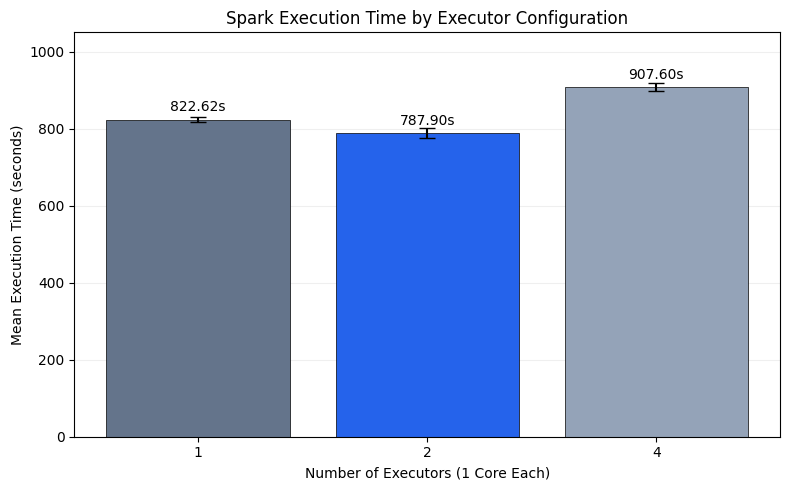

In [ ]:

# Plotting average execution times with standard deviation

executor_counts = [r["executors"] for r in benchmark_summary]
mean_times = [r["mean_seconds"] for r in benchmark_summary]
sd_times = [r["sd_seconds"] for r in benchmark_summary]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [str(n) for n in executor_counts],
    mean_times,
    yerr=sd_times,
    capsize=6,
    color=["#64748b", "#2563eb", "#94a3b8"],
    edgecolor="black",
    linewidth=0.5
)

for bar, mean in zip(bars, mean_times):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        mean + 22,
        f"{mean:.2f}s",
        ha="center",
        fontsize=10
    )

ax.set_title("Spark Execution Time by Executor Configuration")
ax.set_xlabel("Number of Executors (1 Core Each)")
ax.set_ylabel("Mean Execution Time (seconds)")
ax.set_ylim(0, 1050)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### 8.28 Spark Speedup Comparison

I will plot the observed speedup against the ideal linear speedup for each executor configuration. This comparison will help me assess whether adding executors improves runtime on the available Colab hardware.

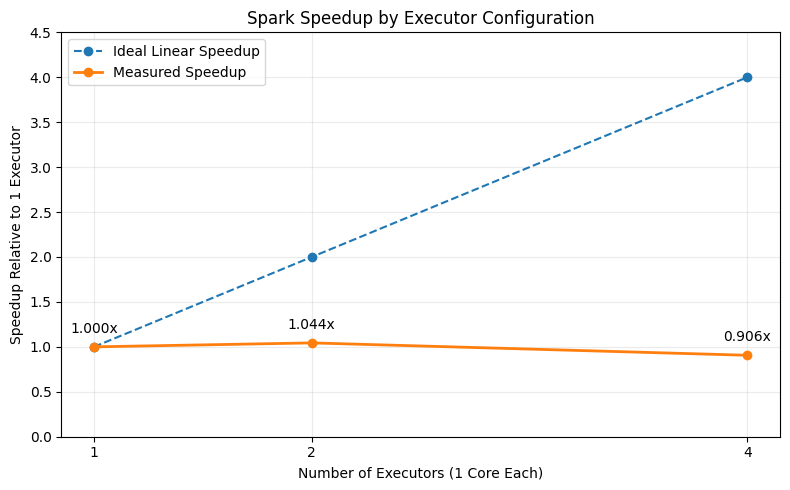

In [ ]:

# Comparing measured and ideal Spark speedup

executor_counts = [r["executors"] for r in benchmark_summary]
measured_speedup = [r["speedup"] for r in benchmark_summary]
ideal_speedup = executor_counts

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    executor_counts,
    ideal_speedup,
    marker="o",
    linestyle="--",
    label="Ideal Linear Speedup"
)

ax.plot(
    executor_counts,
    measured_speedup,
    marker="o",
    linewidth=2,
    label="Measured Speedup"
)

for x, y in zip(executor_counts, measured_speedup):
    ax.annotate(
        f"{y:.3f}x",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Spark Speedup by Executor Configuration")
ax.set_xlabel("Number of Executors (1 Core Each)")
ax.set_ylabel("Speedup Relative to 1 Executor")
ax.set_xticks(executor_counts)
ax.set_ylim(0, 4.5)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


### 8.29 Discussion of Benchmark Results

I found that increasing the number of Spark executors did not consistently reduce execution time.

With **1 executor**, the mean execution time was **822.62 ± 6.35 seconds**. With **2 executors**, it decreased slightly to **787.90 ± 13.10 seconds**, giving a speedup of **1.044×**. With **4 executors**, the mean increased to **907.60 ± 9.84 seconds**, corresponding to a speedup of **0.906×**.

I observed that **2 executors** performed slightly better than the other configurations. The Colab environment provided approximately **2 logical CPU cores**, which were shared among the Spark driver, master, worker processes, and executors. I therefore considered CPU contention, task scheduling, and communication overhead as possible explanations for the slower **4 executor** results.

In a separate development session, I measured **5 input partitions** and a configured shuffle partition count of **200**. These values may help explain limits on parallel data loading, but I did not record the partition counts for every stage of the timed benchmark runs. The benchmark also did not cache the prepared training data, so repeated computation may have contributed to the total execution time.

All configurations processed **5,231,130 records** and returned consistent model evaluation metrics. I therefore found that the executor configuration mainly affected execution time rather than the measured predictive performance.

**Limitations:** These findings reflect the resources available in my Colab environment and may differ on a larger cluster. In the team comparison, both methods include their own complete data preparation steps in their timings, so I will account for the shared cleaning work when comparing results with Samantha's analysis.


### 8.30 Logistic Regression Evaluation Summary

I compared the saved Logistic Regression evaluation metrics across the **1, 2, and 4 executor** configurations. Each configuration produced an **AUC of 0.6384**, an **accuracy of 0.6216**, and a **weighted F1 score of 0.6604**. This weighted score summarizes performance across both classes and differs from the **delayed flight F1 score of 0.3654** reported in Section 7.


In [ ]:

# Checking model performance across executor configurations

print("=== LOGISTIC REGRESSION EVALUATION ===")

for executors in [1, 2, 4]:
    result_file = results_dir / f"benchmark_{executors}_executors_run_1.json"
    result = json.loads(result_file.read_text())

    print(f"\n{executors} Executor(s)")
    print(f"Records processed: {result['rows']:,}")
    print(f"AUC: {result['auc']:.4f}")
    print(f"Accuracy: {result['accuracy']:.4f}")
    print(f"Weighted F1: {result['weighted_f1']:.4f}")


=== LOGISTIC REGRESSION EVALUATION ===

1 Executor(s)
Records processed: 5,231,130
AUC: 0.6384
Accuracy: 0.6216
Weighted F1: 0.6604

2 Executor(s)
Records processed: 5,231,130
AUC: 0.6384
Accuracy: 0.6216
Weighted F1: 0.6604

4 Executor(s)
Records processed: 5,231,130
AUC: 0.6384
Accuracy: 0.6216
Weighted F1: 0.6604


## 9. Conclusion

I used Apache Spark to preprocess the **2015 airline flight delays dataset** and trained a Logistic Regression model to predict whether a flight would arrive at least **15 minutes late**. After cleaning, I retained **5,231,130 records** for classification.

At the validation selected classification threshold of **0.20**, the model achieved an **AUC of 0.6384** and an **accuracy of 62.16%**. The **F1 score for delayed flights was 0.3654**, while the **weighted F1 score across both classes was 0.6604**. These results show that the model identified some delayed flights, although its predictive performance remained limited.

I benchmarked the complete workflow using **1, 2, and 4 executors**, with **3 timed runs per configuration**. The mean execution times were **822.62 ± 6.35 seconds**, **787.90 ± 13.10 seconds**, and **907.60 ± 9.84 seconds**, respectively. The **2 executor** configuration was slightly faster, while **4 executors** were slower in the Colab environment.

I found that increasing the executor count did not guarantee better performance. The limited available CPU resources, process contention, and scheduling overhead may have contributed to this result. The partition configuration observed in my development session also suggests that parallelism during data loading was limited, although I did not measure partition counts for every benchmark stage.

This notebook documents my Logistic Regression method and its Spark performance experiments. I will use these findings alongside Samantha Griffith's statistical analysis when preparing my individual report on the complete team project.
